# Entrenamiento, regularización y optimización aplicada

## Importación de datos - MINST

### Cambio y escalamiento del conjunto de datos

Para esta nueva etapa del proyecto se utilizará un conjunto de datos diferente al empleado anteriormente. En el proyecto inicial se trabajó con un dataset artificial compuesto por puntos distribuidos en forma de anillos pertenecientes a dos clases diferentes. Este conjunto permitió demostrar una de las principales limitaciones de los modelos lineales: la dificultad para separar correctamente clases que no son linealmente separables. A partir de este problema se justificó la necesidad de utilizar modelos con mayor capacidad, como un **perceptrón multicapa (MLP)**.

Sin embargo, en esta etapa se busca ampliar el alcance del MLP y llevarlo hacia un problema más cercano a los escenarios habituales del aprendizaje profundo. Por esta razón, no solo se incrementará la complejidad del modelo, sino también la del conjunto de datos. La intención es trabajar con un problema de mayor escala que permita identificar algunas de las limitaciones que pueden aparecer al utilizar redes neuronales y, posteriormente, aplicar diferentes estrategias para abordarlas y optimizar su funcionamiento.

Para ello se utilizará **MNIST**, uno de los conjuntos de datos más conocidos en problemas de clasificación de imágenes. MNIST contiene **70.000 imágenes de dígitos escritos a mano**, correspondientes a los números del 0 al 9. Cada ejemplo está compuesto por una imagen y su respectiva etiqueta, que indica cuál es el dígito representado.

Las imágenes tienen una resolución de **28 × 28 píxeles**, por lo que cada imagen puede representarse mediante **784 valores de entrada**, correspondientes a los píxeles. El objetivo del modelo será aprender la relación entre estos valores y la etiqueta correspondiente para identificar correctamente qué número representa cada imagen.

El uso de MNIST permitirá aumentar considerablemente la complejidad respecto al problema anterior y, al mismo tiempo, observar de manera práctica diferentes desafíos asociados con el entrenamiento de un MLP. A medida que estos problemas aparezcan, se podrán analizar y aplicar estrategias de optimización para mejorar el desempeño del modelo.


In [ ]:
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

# 1. Cargar los datos de MNIST
(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()

# Combinar los conjuntos de entrenamiento y prueba para un preprocesamiento más sencillo
X_full = np.concatenate((X_train_full, X_test_full), axis=0)
y_full = np.concatenate((y_train_full, y_test_full), axis=0)

print(f"Dimensiones del conjunto de datos completo original (imágenes): {X_full.shape}")
print(f"Dimensiones del conjunto de datos completo original (etiquetas): {y_full.shape}")

# 2. Preprocesar imágenes:
#    a. Normalizar los valores de los píxeles para que estén entre 0 y 1
X_full_normalized = X_full / 255.0

#    b. Aplanar las imágenes en vectores unidimensionales
#    Cada imagen es de 28x28, así que se aplana a 784 características
X_full_flattened = X_full_normalized.reshape(X_full_normalized.shape[0], -1)

print(f"Dimensiones del conjunto de datos aplanado y normalizado: {X_full_flattened.shape}")

# 3. Mantener las etiquetas originales de 0 a 9
# No creamos etiquetas binarias, usamos y_full directamente.
# y_binary = (y_full == 0).astype(int) # Esto se elimina

print(f"Dimensiones de las etiquetas originales: {y_full.shape}")
print(f"Ejemplo de etiquetas originales: {y_full[:10]}")

# 4. Realizar la división 80/20 de entrenamiento y prueba
# Usamos y_full para el split, no y_binary.
X_train, X_test, y_train, y_test = train_test_split(
    X_full_flattened, y_full, test_size=0.2, random_state=42, stratify=y_full
)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")
print(f"Dimensiones de y_test: {y_test.shape}")

# Ahora tienes X_train, y_train, X_test, y_test listos para tu MLP con 10 categorías.


Dimensiones del conjunto de datos completo original (imágenes): (70000, 28, 28)
Dimensiones del conjunto de datos completo original (etiquetas): (70000,)
Dimensiones del conjunto de datos aplanado y normalizado: (70000, 784)
Dimensiones de las etiquetas originales: (70000,)
Ejemplo de etiquetas originales: [5 0 4 1 9 2 1 3 1 4]
Dimensiones de X_train: (56000, 784)
Dimensiones de y_train: (56000,)
Dimensiones de X_test: (14000, 784)
Dimensiones de y_test: (14000,)


## Modelo Base (Modifcado frente al taller anterior)

En esta nueva etapa también es necesario reformular la estructura del MLP utilizado en el taller anterior, principalmente debido al cambio de un problema de clasificación binaria a uno de clasificación multiclase. Mientras que anteriormente la red debía distinguir únicamente entre dos clases, MNIST contiene diez categorías diferentes, correspondientes a los dígitos del 0 al 9. Este cambio implica modificaciones tanto en la capa de salida como en el cálculo de la pérdida y el proceso de retropropagación.

### Funciones de activación y capa de salida
La función de activación ReLU se mantendrá constante en las neuronas de las capas ocultas. No se realizará una experimentación específica con esta función, ya que se considera una alternativa ampliamente utilizada y consistente para este tipo de redes. El cambio principal se realizará en la capa de salida, donde se reemplazará sigmoid por softmax. Sigmoid resulta especialmente adecuada para problemas de clasificación binaria, mientras que softmax permite trabajar con múltiples clases al convertir las diez salidas de la red en una distribución de probabilidades. De esta manera, cada salida representa la probabilidad asociada a un dígito y la de mayor probabilidad determina la predicción final.

### Función de pérdida y backpropagation
El cambio en el número de clases también requiere modificar la función de pérdida. En el problema anterior se utilizaba una entropía asociada a la clasificación binaria, mientras que para MNIST se empleará entropía cruzada categórica multiclase. Esto modifica la forma en que se calcula el error de la red y, consecuentemente, el procedimiento de backpropagation. La derivada utilizada para propagar el error hacia las capas anteriores debe corresponder a la nueva función de pérdida y a la salida softmax.

### Codificación One-Hot
Finalmente, las etiquetas de las diez categorías se transformarán mediante one-hot encoding. En lugar de representar directamente cada dígito como un valor numérico entre 0 y 9, cada etiqueta se convierte en un vector de diez posiciones, donde únicamente una posición representa la clase correcta. Esto permite que las diez salidas de la red se correspondan directamente con las diez categorías del problema y facilita la comparación entre la predicción del modelo y la etiqueta real durante el entrenamiento.

In [ ]:
import numpy as np

class MLP:
    def __init__(self, input_size, hidden_layers_sizes, output_size):
        self.input_size = input_size
        self.hidden_layers_sizes = hidden_layers_sizes
        self.output_size = output_size
        self.weights = []
        self.biases = []
        self.activations = [] # Para almacenar las funciones de activación por capa

        # Define el tamaño de cada capa, incluyendo la entrada y la salida
        layer_sizes = [input_size] + hidden_layers_sizes + [output_size]

        # Inicializar pesos y sesgos para cada capa
        for i in range(len(layer_sizes) - 1):
            # He initialization para pesos (adecuado para ReLU)
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2. / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1])) # Sesgos inicializados a ceros

            self.weights.append(w)
            self.biases.append(b)

            # Asignar funciones de activación:
            # ReLU para capas ocultas, Softmax para la capa de salida (clasificación multiclase)
            if i < len(layer_sizes) - 2: # Capas ocultas
                self.activations.append(self.relu)
            else: # Capa de salida
                self.activations.append(self.softmax) # Cambiado a softmax

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def softmax(self, x):
        # Para evitar problemas numéricos (overflow/underflow)
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        """
        Realiza el paso hacia adelante a través de la red.
        Almacena valores intermedios (Z y A) para la retropropagación.
        """
        activations_cache = [] # Almacena (input_to_layer, output_of_activation)
        Z_cache = []           # Almacena weighted_sum_before_activation

        # Asegura que X sea 2D, incluso para una sola muestra
        if X.ndim == 1:
            X = X.reshape(1, -1)

        A = X # La activación de la capa de entrada es la propia entrada
        activations_cache.append(A)

        for i in range(len(self.weights)):
            W = self.weights[i]
            b = self.biases[i]
            activation_func = self.activations[i]

            Z = np.dot(A, W) + b # Suma ponderada
            A = activation_func(Z) # Aplicar función de activación

            Z_cache.append(Z)
            activations_cache.append(A) # Almacenar la salida de la activación

        return A, {'Z': Z_cache, 'A': activations_cache}

    def compute_loss(self, y_true, y_pred):
        """
        Calcula la pérdida de entropía cruzada categórica.
        y_true: etiquetas verdaderas (one-hot encoded)
        y_pred: probabilidades predichas (salida de la softmax)
        """
        # Recorta las predicciones para evitar log(0)
        y_pred = np.clip(y_pred, 1e-10, 1 - 1e-10)

        # Pérdida de entropía cruzada
        loss = -np.sum(y_true * np.log(y_pred)) / y_true.shape[0]

        return loss

    def backward(self, X, y_true, y_pred, cache):
        """
        Realiza el paso hacia atrás (retropropagación) para calcular gradientes.
        X: datos de entrada (usado para el gradiente de la primera capa)
        y_true: etiquetas verdaderas (one-hot encoded)
        y_pred: probabilidades predichas del paso hacia adelante
        cache: diccionario que contiene los valores Z y A del paso hacia adelante
        """
        grads_W = [np.zeros_like(w) for w in self.weights]
        grads_b = [np.zeros_like(b) for b in self.biases]

        m = X.shape[0] # Número de muestras

        A_cache = cache['A']
        Z_cache = cache['Z']

        # Gradientes de la capa de salida (dL/dZ_L para softmax + CCE)
        # dZ_L = y_pred - y_true para softmax con CCE (cuando y_true es one-hot)
        dZ = (y_pred - y_true) / m # Dividir por m aquí para promediar el gradiente

        # Gradientes para los pesos y sesgos de la capa de salida
        grads_W[-1] = np.dot(A_cache[-2].T, dZ)
        grads_b[-1] = np.sum(dZ, axis=0, keepdims=True)

        # Retropropagación a través de las capas ocultas
        for i in reversed(range(len(self.weights) - 1)):
            W_current = self.weights[i+1]
            Z_current = Z_cache[i] # Z para la capa oculta actual

            dA_prev = np.dot(dZ, W_current.T) # dL/dA_prev

            # dL/dZ_current = dL/dA_current * dA_current/dZ_current
            # dA_current/dZ_current es la derivada de la activación ReLU
            dZ = dA_prev * self.relu_derivative(Z_current)

            grads_W[i] = np.dot(A_cache[i].T, dZ)
            grads_b[i] = np.sum(dZ, axis=0, keepdims=True)

        return grads_W, grads_b

    def train(self, X_train, y_train, epochs, learning_rate):
        """
        Entrena la MLP usando descenso de gradiente estocástico.
        y_train debe estar one-hot encoded.
        """
        # Asegurarse de que y_train esté one-hot encoded si no lo está ya
        if y_train.ndim == 1:
            y_train_one_hot = np.eye(self.output_size)[y_train] # Convertir a one-hot
        else:
            y_train_one_hot = y_train

        for epoch in range(epochs):
            # Mezcla los datos para el descenso de gradiente estocástico
            indices = np.arange(X_train.shape[0])
            np.random.shuffle(indices)
            X_shuffled = X_train[indices]
            y_shuffled = y_train_one_hot[indices] # Usar y_train_one_hot

            total_loss = 0
            for i in range(X_shuffled.shape[0]):
                x_sample = X_shuffled[i:i+1] # Mantener dimensiones para consistencia (batch_size=1)
                y_sample = y_shuffled[i:i+1]

                # Paso hacia adelante
                y_pred, cache = self.forward(x_sample)
                loss = self.compute_loss(y_sample, y_pred)
                total_loss += loss

                # Paso hacia atrás
                grads_W, grads_b = self.backward(x_sample, y_sample, y_pred, cache)

                # Actualizar pesos y sesgos
                for j in range(len(self.weights)):
                    self.weights[j] -= learning_rate * grads_W[j]
                    self.biases[j] -= learning_rate * grads_b[j]

            # Opcional: imprimir la pérdida cada ciertas épocas
            # if (epoch + 1) % 10 == 0:
            #     print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss / X_shuffled.shape[0]:.4f}")

    def evaluate(self, X_test, y_test):
        """
        Evalúa la MLP con los datos de prueba.
        y_test debe contener las etiquetas numéricas originales (no one-hot).
        """
        y_pred_probs, _ = self.forward(X_test)
        # La clase predicha es la que tiene la mayor probabilidad
        y_pred_classes = np.argmax(y_pred_probs, axis=1)

        accuracy = np.mean(y_pred_classes == y_test) * 100
        print(f"Evaluation Accuracy: {accuracy:.2f}%")
        return accuracy

In [ ]:
import numpy as np

class MLP_L1:
    def __init__(self, input_size, hidden_layers_sizes, output_size, lambda_l1=0.0):
        self.input_size = input_size
        self.hidden_layers_sizes = hidden_layers_sizes
        self.output_size = output_size
        self.lambda_l1 = lambda_l1 # Añadir el parámetro de regularización L1
        self.weights = []
        self.biases = []
        self.activations = [] # Para almacenar las funciones de activación por capa

        # Define el tamaño de cada capa, incluyendo la entrada y la salida
        layer_sizes = [input_size] + hidden_layers_sizes + [output_size]

        # Inicializar pesos y sesgos para cada capa
        for i in range(len(layer_sizes) - 1):
            # He initialization para pesos (adecuado para ReLU)
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2. / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1])) # Sesgos inicializados a ceros

            self.weights.append(w)
            self.biases.append(b)

            # Asignar funciones de activación:
            # ReLU para capas ocultas, Softmax para la capa de salida (clasificación multiclase)
            if i < len(layer_sizes) - 2: # Capas ocultas
                self.activations.append(self.relu)
            else: # Capa de salida
                self.activations.append(self.softmax) # Cambiado a softmax

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def softmax(self, x):
        # Para evitar problemas numéricos (overflow/underflow)
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        """
        Realiza el paso hacia adelante a través de la red.
        Almacena valores intermedios (Z y A) para la retropropagación.
        """
        activations_cache = [] # Almacena (input_to_layer, output_of_activation)
        Z_cache = []           # Almacena weighted_sum_before_activation

        # Asegura que X sea 2D, incluso para una sola muestra
        if X.ndim == 1:
            X = X.reshape(1, -1)

        A = X # La activación de la capa de entrada es la propia entrada
        activations_cache.append(A)

        for i in range(len(self.weights)):
            W = self.weights[i]
            b = self.biases[i]
            activation_func = self.activations[i]

            Z = np.dot(A, W) + b # Suma ponderada
            A = activation_func(Z) # Aplicar función de activación

            Z_cache.append(Z)
            activations_cache.append(A) # Almacenar la salida de la activación

        return A, {'Z': Z_cache, 'A': activations_cache}

    def compute_loss(self, y_true, y_pred):
        """
        Calcula la pérdida de entropía cruzada categórica.
        y_true: etiquetas verdaderas (one-hot encoded)
        y_pred: probabilidades predichas (salida de la softmax)
        """
        # Recorta las predicciones para evitar log(0)
        y_pred = np.clip(y_pred, 1e-10, 1 - 1e-10)

        # Pérdida de entropía cruzada
        loss = -np.sum(y_true * np.log(y_pred)) / y_true.shape[0]

        # Añadir término de regularización L1 si lambda_l1 > 0
        if self.lambda_l1 > 0:
            l1_penalty = 0
            for w in self.weights:
                l1_penalty += np.sum(np.abs(w)) # Suma de los valores absolutos de los pesos
            loss += (self.lambda_l1 / (2 * y_true.shape[0])) * l1_penalty # Dividir por 2*m para consistencia con la práctica común y la derivada

        return loss

    def backward(self, X, y_true, y_pred, cache):
        """
        Realiza el paso hacia atrás (retropropagación) para calcular gradientes.
        X: datos de entrada (usado para el gradiente de la primera capa)
        y_true: etiquetas verdaderas (one-hot encoded)
        y_pred: probabilidades predichas del paso hacia adelante
        cache: diccionario que contiene los valores Z y A del paso hacia adelante
        """
        grads_W = [np.zeros_like(w) for w in self.weights]
        grads_b = [np.zeros_like(b) for b in self.biases]

        m = X.shape[0] # Número de muestras

        A_cache = cache['A']
        Z_cache = cache['Z']

        # Gradientes de la capa de salida (dL/dZ_L para softmax + CCE)
        # dZ_L = y_pred - y_true para softmax con CCE (cuando y_true es one-hot)
        dZ = (y_pred - y_true) / m # Dividir por m aquí para promediar el gradiente

        # Gradientes para los pesos y sesgos de la capa de salida
        grads_W[-1] = np.dot(A_cache[-2].T, dZ)
        grads_b[-1] = np.sum(dZ, axis=0, keepdims=True)

        # Añadir gradiente de regularización L1 para la capa de salida
        if self.lambda_l1 > 0:
            grads_W[-1] += (self.lambda_l1 / m) * np.sign(self.weights[-1])

        # Retropropagación a través de las capas ocultas
        for i in reversed(range(len(self.weights) - 1)):
            W_current = self.weights[i+1]
            Z_current = Z_cache[i] # Z para la capa oculta actual

            dA_prev = np.dot(dZ, W_current.T) # dL/dA_prev

            # dL/dZ_current = dL/dA_current * dA_current/dZ_current
            # dA_current/dZ_current es la derivada de la activación ReLU
            dZ = dA_prev * self.relu_derivative(Z_current)

            grads_W[i] = np.dot(A_cache[i].T, dZ)
            grads_b[i] = np.sum(dZ, axis=0, keepdims=True)

            # Añadir gradiente de regularización L1 para las capas ocultas
            if self.lambda_l1 > 0:
                grads_W[i] += (self.lambda_l1 / m) * np.sign(self.weights[i])

        return grads_W, grads_b

    def train(self, X_train, y_train, epochs, learning_rate):
        """
        Entrena la MLP usando descenso de gradiente estocástico.
        y_train debe estar one-hot encoded.
        """
        # Asegurarse de que y_train esté one-hot encoded si no lo está ya
        if y_train.ndim == 1:
            y_train_one_hot = np.eye(self.output_size)[y_train] # Convertir a one-hot
        else:
            y_train_one_hot = y_train

        for epoch in range(epochs):
            # Mezcla los datos para el descenso de gradiente estocástico
            indices = np.arange(X_train.shape[0])
            np.random.shuffle(indices)
            X_shuffled = X_train[indices]
            y_shuffled = y_train_one_hot[indices] # Usar y_train_one_hot

            total_loss = 0
            for i in range(X_shuffled.shape[0]):
                x_sample = X_shuffled[i:i+1] # Mantener dimensiones para consistencia (batch_size=1)
                y_sample = y_shuffled[i:i+1]

                # Paso hacia adelante
                y_pred, cache = self.forward(x_sample)
                loss = self.compute_loss(y_sample, y_pred)
                total_loss += loss

                # Paso hacia atrás
                grads_W, grads_b = self.backward(x_sample, y_sample, y_pred, cache)

                # Actualizar pesos y sesgos
                for j in range(len(self.weights)):
                    self.weights[j] -= learning_rate * grads_W[j]
                    self.biases[j] -= learning_rate * grads_b[j]

            # Opcional: imprimir la pérdida cada ciertas épocas
            # if (epoch + 1) % 10 == 0:
            #     print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss / X_shuffled.shape[0]:.4f}")

    def evaluate(self, X_test, y_test):
        """
        Evalúa la MLP con los datos de prueba.
        y_test debe contener las etiquetas numéricas originales (no one-hot).
        """
        y_pred_probs, _ = self.forward(X_test)
        # La clase predicha es la que tiene la mayor probabilidad
        y_pred_classes = np.argmax(y_pred_probs, axis=1)

        accuracy = np.mean(y_pred_classes == y_test) * 100
        print(f"Evaluation Accuracy: {accuracy:.2f}%")
        return accuracy

In [ ]:
import numpy as np

class MLP_Optimizers:
    def __init__(self, input_size, hidden_layers_sizes, output_size,
                 optimizer_type='sgd', batch_size=32,
                 momentum_beta=0.9, adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-8):
        self.input_size = input_size
        self.hidden_layers_sizes = hidden_layers_sizes
        self.output_size = output_size
        self.optimizer_type = optimizer_type
        self.batch_size = batch_size
        self.momentum_beta = momentum_beta
        self.adam_beta1 = adam_beta1
        self.adam_beta2 = adam_beta2
        self.adam_epsilon = adam_epsilon

        self.weights = []
        self.biases = []
        self.activations = []

        # Define el tamaño de cada capa, incluyendo la entrada y la salida
        layer_sizes = [input_size] + hidden_layers_sizes + [output_size]

        # Inicializar pesos y sesgos
        for i in range(len(layer_sizes) - 1):
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2. / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1]))
            self.weights.append(w)
            self.biases.append(b)

            if i < len(layer_sizes) - 2:
                self.activations.append(self.relu)
            else:
                self.activations.append(self.softmax)

        # Inicializar parámetros específicos del optimizador
        if self.optimizer_type == 'momentum':
            self.v_weights = [np.zeros_like(w) for w in self.weights]
            self.v_biases = [np.zeros_like(b) for b in self.biases]
        elif self.optimizer_type == 'adam':
            self.m_weights = [np.zeros_like(w) for w in self.weights]
            self.v_weights_adam = [np.zeros_like(w) for w in self.weights]
            self.m_biases = [np.zeros_like(b) for b in self.biases]
            self.v_biases_adam = [np.zeros_like(b) for b in self.biases]
            self.t = 0 # Contador para la corrección de sesgo en Adam

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def softmax(self, x):
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        if X.ndim == 1:
            X = X.reshape(1, -1)
        A = X
        activations_cache = [A]
        Z_cache = []

        for i in range(len(self.weights)):
            W = self.weights[i]
            b = self.biases[i]
            activation_func = self.activations[i]

            Z = np.dot(A, W) + b
            A = activation_func(Z)

            Z_cache.append(Z)
            activations_cache.append(A)
        return A, {'Z': Z_cache, 'A': activations_cache}

    def compute_loss(self, y_true, y_pred):
        y_pred = np.clip(y_pred, 1e-10, 1 - 1e-10)
        loss = -np.sum(y_true * np.log(y_pred)) / y_true.shape[0]
        return loss

    def backward(self, X, y_true, y_pred, cache):
        grads_W = [np.zeros_like(w) for w in self.weights]
        grads_b = [np.zeros_like(b) for b in self.biases]
        m = X.shape[0]

        A_cache = cache['A']
        Z_cache = cache['Z']

        dZ = (y_pred - y_true) / m

        grads_W[-1] = np.dot(A_cache[-2].T, dZ)
        grads_b[-1] = np.sum(dZ, axis=0, keepdims=True)

        for i in reversed(range(len(self.weights) - 1)):
            W_current = self.weights[i+1]
            Z_current = Z_cache[i]

            dA_prev = np.dot(dZ, W_current.T)
            dZ = dA_prev * self.relu_derivative(Z_current)

            grads_W[i] = np.dot(A_cache[i].T, dZ)
            grads_b[i] = np.sum(dZ, axis=0, keepdims=True)
        return grads_W, grads_b

    def train(self, X_train, y_train, epochs, learning_rate):
        if y_train.ndim == 1:
            y_train_one_hot = np.eye(self.output_size)[y_train]
        else:
            y_train_one_hot = y_train

        num_samples = X_train.shape[0]
        num_batches = int(np.ceil(num_samples / self.batch_size))

        # These are used by the helper function for logging
        train_losses = []
        test_losses = []

        for epoch in range(epochs):
            indices = np.arange(num_samples)
            np.random.shuffle(indices)

            epoch_train_loss = 0
            if self.optimizer_type == 'adam':
                self.t += 1 # Increment time step for Adam bias correction

            for batch_idx in range(num_batches):
                start = batch_idx * self.batch_size
                end = min((batch_idx + 1) * self.batch_size, num_samples)
                batch_indices = indices[start:end]

                X_batch = X_train[batch_indices]
                y_batch_one_hot = y_train_one_hot[batch_indices]

                y_pred, cache = self.forward(X_batch)
                loss = self.compute_loss(y_batch_one_hot, y_pred)
                epoch_train_loss += loss * X_batch.shape[0] # Accumulate total loss for average

                grads_W, grads_b = self.backward(X_batch, y_batch_one_hot, y_pred, cache)

                for j in range(len(self.weights)):
                    if self.optimizer_type == 'sgd':
                        self.weights[j] -= learning_rate * grads_W[j]
                        self.biases[j] -= learning_rate * grads_b[j]
                    elif self.optimizer_type == 'momentum':
                        self.v_weights[j] = self.momentum_beta * self.v_weights[j] - learning_rate * grads_W[j]
                        self.v_biases[j] = self.momentum_beta * self.v_biases[j] - learning_rate * grads_b[j]
                        self.weights[j] += self.v_weights[j]
                        self.biases[j] += self.v_biases[j]
                    elif self.optimizer_type == 'adam':
                        # Update biased first moment estimate
                        self.m_weights[j] = self.adam_beta1 * self.m_weights[j] + (1 - self.adam_beta1) * grads_W[j]
                        self.m_biases[j] = self.adam_beta1 * self.m_biases[j] + (1 - self.adam_beta1) * grads_b[j]

                        # Update biased second raw moment estimate
                        self.v_weights_adam[j] = self.adam_beta2 * self.v_weights_adam[j] + (1 - self.adam_beta2) * (grads_W[j] ** 2)
                        self.v_biases_adam[j] = self.adam_beta2 * self.v_biases_adam[j] + (1 - self.adam_beta2) * (grads_b[j] ** 2)

                        # Compute bias-corrected first moment estimate
                        m_hat_W = self.m_weights[j] / (1 - self.adam_beta1 ** self.t)
                        m_hat_b = self.m_biases[j] / (1 - self.adam_beta1 ** self.t)

                        # Compute bias-corrected second raw moment estimate
                        v_hat_W = self.v_weights_adam[j] / (1 - self.adam_beta2 ** self.t)
                        v_hat_b = self.v_biases_adam[j] / (1 - self.adam_beta2 ** self.t)

                        # Update weights and biases
                        self.weights[j] -= learning_rate * m_hat_W / (np.sqrt(v_hat_W) + self.adam_epsilon)
                        self.biases[j] -= learning_rate * m_hat_b / (np.sqrt(v_hat_b) + self.adam_epsilon)

            # Calculate average epoch loss for train set
            avg_epoch_train_loss = epoch_train_loss / num_samples
            train_losses.append(avg_epoch_train_loss)

            # Calculate loss on test set after each epoch
            y_test_pred_probs, _ = self.forward(X_test)
            avg_epoch_test_loss = self.compute_loss(y_test_one_hot, y_test_pred_probs)
            test_losses.append(avg_epoch_test_loss)

            # Print progress only if called from the helper function
            # if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
            #     print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {avg_epoch_train_loss:.4f}, Pérdida de Prueba: {avg_epoch_test_loss:.4f}")

        return train_losses, test_losses

    def evaluate(self, X_test, y_test):
        y_pred_probs, _ = self.forward(X_test)
        y_pred_classes = np.argmax(y_pred_probs, axis=1)

        accuracy = np.mean(y_pred_classes == y_test) * 100
        print(f"Evaluation Accuracy: {accuracy:.2f}%")
        return accuracy

# Entrenamiento del primero modelo sin ninguna optimización (Baseline)

Como punto de partida se establece un **modelo baseline** adaptado al problema de clasificación multiclase planteado con el dataset MNIST. La arquitectura estará compuesta por una capa de entrada de **784 neuronas**, correspondientes a los 28 × 28 píxeles de cada imagen, seguida de **dos capas ocultas de 32 neuronas cada una** y, finalmente, una capa de salida de **10 neuronas**, una por cada categoría de dígito.

Esta arquitectura se plantea deliberadamente como un modelo relativamente pequeño, principalmente para mantener unos costos de procesamiento moderados y establecer una referencia clara frente a las modificaciones posteriores. Por lo tanto, el baseline no busca maximizar inicialmente el desempeño, sino proporcionar un punto de comparación sobre el cual se puedan medir los efectos de los diferentes cambios realizados a la arquitectura de la red.

A partir de este modelo se evaluarán las modificaciones posteriores, permitiendo determinar cómo los cambios en la cantidad de neuronas y en la profundidad de la red afectan su comportamiento sobre el problema de clasificación de MNIST.


Inicializando MLP con input_size=784, hidden_layers_sizes=[32, 32], output_size=10

Entrenando el modelo: Base MLP Model 32x32 con 30 épocas y learning_rate=0.01...
Época 1/30, Pérdida de Entrenamiento: 0.2859, Pérdida de Prueba: 0.1804
Época 10/30, Pérdida de Entrenamiento: 0.0821, Pérdida de Prueba: 0.1276
Época 20/30, Pérdida de Entrenamiento: 0.0621, Pérdida de Prueba: 0.1651
Época 30/30, Pérdida de Entrenamiento: 0.0563, Pérdida de Prueba: 0.1894

Entrenamiento completado.

Evaluando el modelo en el conjunto de prueba...
Evaluation Accuracy: 96.50%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1381
           1       0.99      0.99      0.99      1575
           2       0.96      0.98      0.97      1398
           3       0.93      0.98      0.95      1428
           4       0.96      0.97      0.97      1365
           5       0.96      0.93      0.95      1263
           6       0.98      0.98 

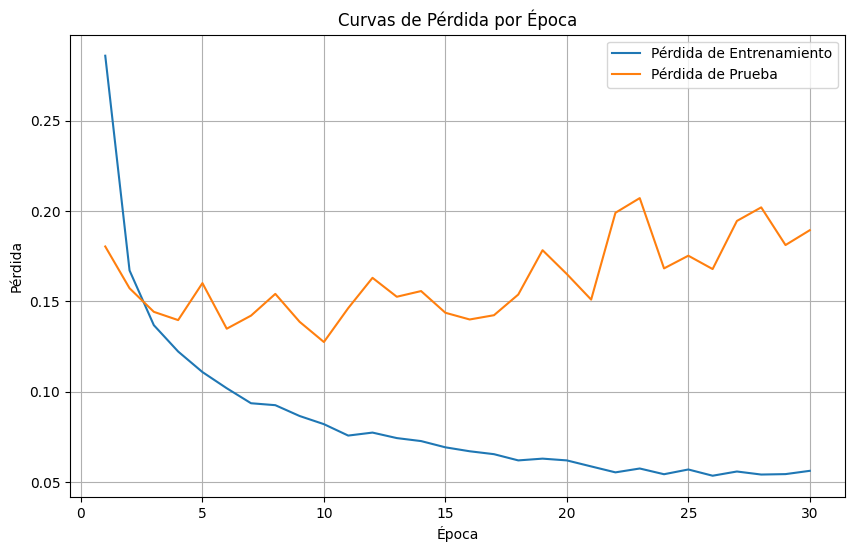


DataFrame de rendimiento del modelo:

             Model Name  Accuracy  Precision (weighted)  Recall (weighted)  \
0        Base MLP Model    0.9785              0.978655             0.9785   
1  Base MLP Model 32x32    0.9650              0.965129             0.9650   

   F1-score (weighted)  Training Loss  Test Loss  
0             0.978516       0.010729   0.144944  
1             0.964930       0.056343   0.189396  


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import numpy as np

# 1. Definir parámetros del modelo
input_size = X_train.shape[1] # 784 píxeles (28x28 aplanado)
hidden_layers_sizes = [32, 32] # Dos capas ocultas con 128 y 64 neuronas
output_size = len(np.unique(y_train)) # 10 clases (0-9)
epochs = 30 # Número de épocas
learning_rate = 0.01 # Tasa de aprendizaje

# 2. Instanciar el modelo MLP
print(f"Inicializando MLP con input_size={input_size}, hidden_layers_sizes={hidden_layers_sizes}, output_size={output_size}")
mlp_model = MLP(input_size, hidden_layers_sizes, output_size)

# Preparar las etiquetas one-hot encoding para el cálculo de la pérdida durante el entrenamiento y la prueba
# y_train_one_hot y y_test_one_hot se usarán para compute_loss
# y_train y y_test (originales) se usarán para mlp_model.evaluate y classification_report
y_train_one_hot = np.eye(output_size)[y_train]
y_test_one_hot = np.eye(output_size)[y_test]

# Listas para almacenar la pérdida durante el entrenamiento y la evaluación en cada época
train_losses = []
test_losses = []

model_name = 'Base MLP Model 32x32'
print(f"\nEntrenando el modelo: {model_name} con {epochs} épocas y learning_rate={learning_rate}...")

# Bucle de entrenamiento manual para recopilar pérdidas por época
for epoch in range(epochs):
    # Mezclar los índices para el Descenso de Gradiente Estocástico (SGD)
    indices = np.arange(X_train.shape[0])
    np.random.shuffle(indices)
    X_shuffled = X_train[indices]
    y_shuffled_one_hot = y_train_one_hot[indices]

    epoch_train_loss = 0
    # Iterar sobre cada muestra para SGD (tamaño de "batch" de 1)
    for i in range(X_shuffled.shape[0]):
        x_sample = X_shuffled[i:i+1]
        y_sample = y_shuffled_one_hot[i:i+1]

        # Paso hacia adelante
        y_pred, cache = mlp_model.forward(x_sample)
        loss = mlp_model.compute_loss(y_sample, y_pred)
        epoch_train_loss += loss

        # Paso hacia atrás
        grads_W, grads_b = mlp_model.backward(x_sample, y_sample, y_pred, cache)

        # Actualizar pesos y sesgos
        for j in range(len(mlp_model.weights)):
            mlp_model.weights[j] -= learning_rate * grads_W[j]
            mlp_model.biases[j] -= learning_rate * grads_b[j]

    # Calcular la pérdida promedio de entrenamiento para la época
    avg_epoch_train_loss = epoch_train_loss / X_shuffled.shape[0]
    train_losses.append(avg_epoch_train_loss)

    # Calcular la pérdida en el conjunto de prueba después de cada época
    y_test_pred_probs, _ = mlp_model.forward(X_test)
    avg_epoch_test_loss = mlp_model.compute_loss(y_test_one_hot, y_test_pred_probs)
    test_losses.append(avg_epoch_test_loss)

    # Imprimir el progreso cada 10 épocas o al principio/final
    if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
        print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {avg_epoch_train_loss:.4f}, Pérdida de Prueba: {avg_epoch_test_loss:.4f}")

print("\nEntrenamiento completado.\n")

# 3. Evaluar el modelo en el conjunto de prueba
print("Evaluando el modelo en el conjunto de prueba...")
accuracy = mlp_model.evaluate(X_test, y_test) # mlp_model.evaluate ya imprime y devuelve la precisión

# Obtener predicciones para el reporte de clasificación
y_pred_probs_test, _ = mlp_model.forward(X_test)
y_pred_classes_test = np.argmax(y_pred_probs_test, axis=1)

# 4. Generar el Informe de Clasificación
print("\nInforme de Clasificación:")
report = classification_report(y_test, y_pred_classes_test, output_dict=True)
print(classification_report(y_test, y_pred_classes_test))

# 5. Graficar las Curvas de Pérdida
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Pérdida de Entrenamiento')
plt.plot(range(1, epochs + 1), test_losses, label='Pérdida de Prueba')
plt.title('Curvas de Pérdida por Época')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)
plt.show()

# 6. Almacenar Estadísticas en un DataFrame
# Inicializar el DataFrame si no existe en el scope global
if 'model_performance_df' not in globals():
    model_performance_df = pd.DataFrame(columns=['Model Name', 'Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1-score (weighted)', 'Training Loss', 'Test Loss'])

# Extraer métricas clave para el DataFrame
accuracy_val = accuracy / 100.0 # Convertir de porcentaje a fracción
precision_weighted = report['weighted avg']['precision']
recall_weighted = report['weighted avg']['recall']
f1_weighted = report['weighted avg']['f1-score']

new_model_stats = pd.DataFrame([{ # Crear un nuevo DataFrame para las estadísticas del modelo actual
    'Model Name': model_name,
    'Accuracy': accuracy_val,
    'Precision (weighted)': precision_weighted,
    'Recall (weighted)': recall_weighted,
    'F1-score (weighted)': f1_weighted,
    'Training Loss': train_losses[-1], # Última pérdida de entrenamiento
    'Test Loss': test_losses[-1]      # Última pérdida de prueba
}])

# Concatenar las nuevas estadísticas al DataFrame global
model_performance_df = pd.concat([model_performance_df, new_model_stats], ignore_index=True)

print("\nDataFrame de rendimiento del modelo:\n")
print(model_performance_df)


### Experimento 1: Arquitecturas de Red


El primer experimento busca analizar cómo los cambios en la **arquitectura de la red neuronal** afectan su desempeño. Para esto, se parte del modelo baseline y se plantean dos modificaciones diferentes, con el objetivo de comparar el efecto de aumentar el número de neuronas frente al de aumentar la profundidad de la red.

La primera prueba corresponde a una expansión de la cantidad de neuronas por capa, manteniendo las dos capas ocultas, pero aumentando su tamaño a **128 y 64 neuronas**, respectivamente. Con esto se busca evaluar si una mayor capacidad de representación dentro de las capas existentes permite obtener mejores resultados.

La segunda prueba mantiene el tamaño de **32 neuronas por capa**, pero incorpora una tercera capa oculta, obteniendo una arquitectura de **32-32-32 neuronas**. En este caso, el objetivo es analizar el efecto de incrementar la profundidad de la red sin aumentar significativamente la cantidad de neuronas utilizadas en cada capa.

De esta manera, el experimento permite contrastar dos formas de incrementar la capacidad del MLP: una arquitectura **menos profunda pero más ancha**, frente a una arquitectura **más profunda pero con capas más pequeñas**. Las diferencias observadas servirán para analizar cómo la distribución de las neuronas dentro de la red influye en el proceso de aprendizaje y en los resultados obtenidos.



--- Experimentando con la arquitectura: MLP 2x64 --- 
Entrenando el modelo: MLP 2x64 con 30 épocas y learning_rate=0.01...
Época 1/30, Pérdida de Entrenamiento: 0.2477, Pérdida de Prueba: 0.1361
Época 10/30, Pérdida de Entrenamiento: 0.0495, Pérdida de Prueba: 0.1678
Época 20/30, Pérdida de Entrenamiento: 0.0327, Pérdida de Prueba: 0.1568
Época 30/30, Pérdida de Entrenamiento: 0.0366, Pérdida de Prueba: 0.1848

Entrenamiento de MLP 2x64 completado.

Evaluando el modelo MLP 2x64 en el conjunto de prueba...
Evaluation Accuracy: 97.33%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1381
           1       0.98      0.99      0.98      1575
           2       0.98      0.97      0.97      1398
           3       0.97      0.97      0.97      1428
           4       0.95      0.98      0.97      1365
           5       0.97      0.97      0.97      1263
           6       0.99      0.98      0.98      1375


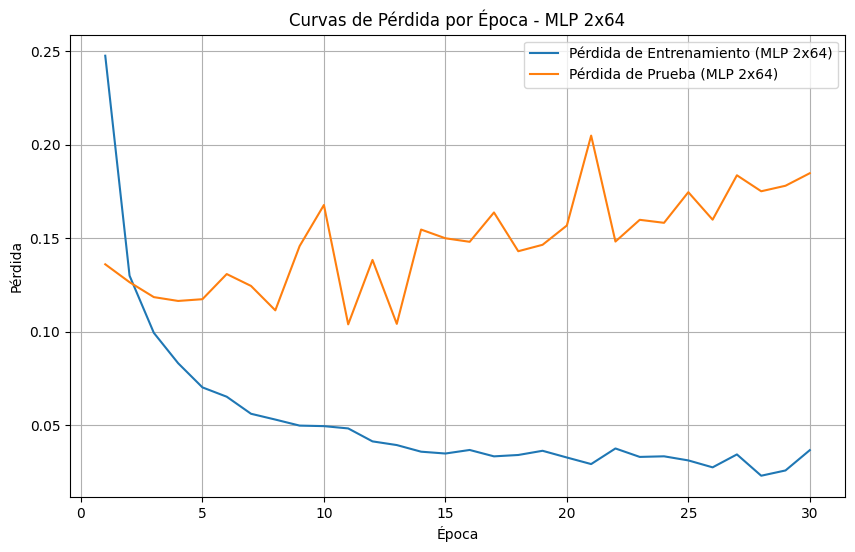


--- Experimentando con la arquitectura: MLP 3x32 --- 
Entrenando el modelo: MLP 3x32 con 30 épocas y learning_rate=0.01...
Época 1/30, Pérdida de Entrenamiento: 0.3164, Pérdida de Prueba: 0.1861
Época 10/30, Pérdida de Entrenamiento: 0.0847, Pérdida de Prueba: 0.1280
Época 20/30, Pérdida de Entrenamiento: 0.0635, Pérdida de Prueba: 0.1625
Época 30/30, Pérdida de Entrenamiento: 0.0530, Pérdida de Prueba: 0.1730

Entrenamiento de MLP 3x32 completado.

Evaluando el modelo MLP 3x32 en el conjunto de prueba...
Evaluation Accuracy: 96.54%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      1381
           1       0.99      0.98      0.98      1575
           2       0.97      0.97      0.97      1398
           3       0.96      0.96      0.96      1428
           4       0.96      0.96      0.96      1365
           5       0.95      0.95      0.95      1263
           6       0.97      0.98      0.98      1375


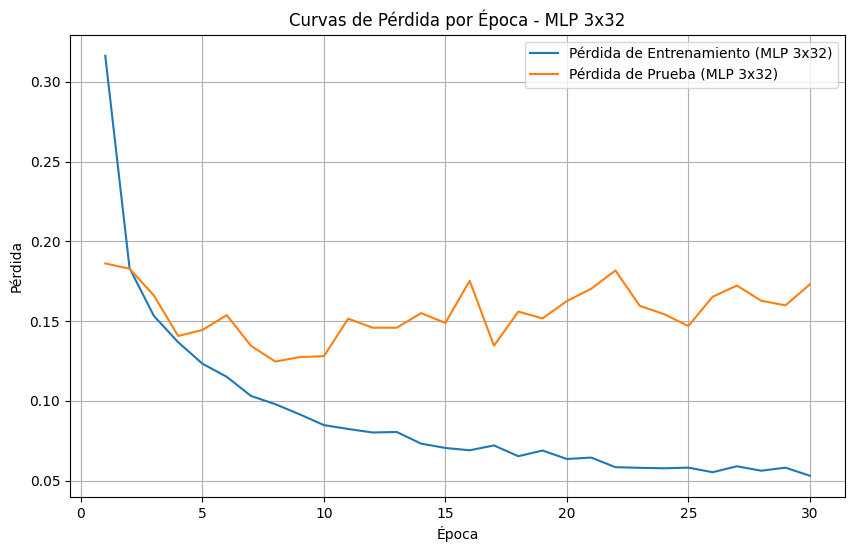


DataFrame de rendimiento final de todos los modelos:

             Model Name  Accuracy  Precision (weighted)  Recall (weighted)  \
0        Base MLP Model  0.978500              0.978655           0.978500   
1  Base MLP Model 32x32  0.965000              0.965129           0.965000   
2              MLP 2x64  0.973286              0.973383           0.973286   
3              MLP 3x32  0.965429              0.965578           0.965429   

   F1-score (weighted)  Training Loss  Test Loss  
0             0.978516       0.010729   0.144944  
1             0.964930       0.056343   0.189396  
2             0.973260       0.036617   0.184791  
3             0.965421       0.053000   0.172955  


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Asegurarse de que las variables globales existan o definirlas si es necesario
# (normalmente ya deberían estar definidas por celdas anteriores)
# X_train, y_train, X_test, y_test, y_train_one_hot, y_test_one_hot, output_size, MLP

def train_and_evaluate_mlp(
    hidden_layers_sizes,
    epochs,
    learning_rate,
    model_name,
    X_train,
    y_train,
    X_test,
    y_test,
    output_size,
    y_train_one_hot,
    y_test_one_hot,
    model_performance_df_global
):
    print(f"\n--- Experimentando con la arquitectura: {model_name} --- ")
    input_size = X_train.shape[1]
    mlp_model = MLP(input_size, hidden_layers_sizes, output_size)

    train_losses = []
    test_losses = []

    print(f"Entrenando el modelo: {model_name} con {epochs} épocas y learning_rate={learning_rate}...")

    for epoch in range(epochs):
        indices = np.arange(X_train.shape[0])
        np.random.shuffle(indices)
        X_shuffled = X_train[indices]
        y_shuffled_one_hot = y_train_one_hot[indices]

        epoch_train_loss = 0
        for i in range(X_shuffled.shape[0]):
            x_sample = X_shuffled[i:i+1]
            y_sample = y_shuffled_one_hot[i:i+1]

            y_pred, cache = mlp_model.forward(x_sample)
            loss = mlp_model.compute_loss(y_sample, y_pred)
            epoch_train_loss += loss

            grads_W, grads_b = mlp_model.backward(x_sample, y_sample, y_pred, cache)

            for j in range(len(mlp_model.weights)):
                mlp_model.weights[j] -= learning_rate * grads_W[j]
                mlp_model.biases[j] -= learning_rate * grads_b[j]

        avg_epoch_train_loss = epoch_train_loss / X_shuffled.shape[0]
        train_losses.append(avg_epoch_train_loss)

        y_test_pred_probs, _ = mlp_model.forward(X_test)
        avg_epoch_test_loss = mlp_model.compute_loss(y_test_one_hot, y_test_pred_probs)
        test_losses.append(avg_epoch_test_loss)

        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {avg_epoch_train_loss:.4f}, Pérdida de Prueba: {avg_epoch_test_loss:.4f}")

    print(f"\nEntrenamiento de {model_name} completado.\n")

    print(f"Evaluando el modelo {model_name} en el conjunto de prueba...")
    accuracy = mlp_model.evaluate(X_test, y_test)

    y_pred_probs_test, _ = mlp_model.forward(X_test)
    y_pred_classes_test = np.argmax(y_pred_probs_test, axis=1)

    print("\nInforme de Clasificación:")
    report = classification_report(y_test, y_pred_classes_test, output_dict=True)
    print(classification_report(y_test, y_pred_classes_test))

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, epochs + 1), train_losses, label=f'Pérdida de Entrenamiento ({model_name})')
    plt.plot(range(1, epochs + 1), test_losses, label=f'Pérdida de Prueba ({model_name})')
    plt.title(f'Curvas de Pérdida por Época - {model_name}')
    plt.xlabel('Época')
    plt.ylabel('Pérdida')
    plt.legend()
    plt.grid(True)
    plt.show()

    accuracy_val = accuracy / 100.0
    precision_weighted = report['weighted avg']['precision']
    recall_weighted = report['weighted avg']['recall']
    f1_weighted = report['weighted avg']['f1-score']

    new_model_stats = pd.DataFrame([{
        'Model Name': model_name,
        'Accuracy': accuracy_val,
        'Precision (weighted)': precision_weighted,
        'Recall (weighted)': recall_weighted,
        'F1-score (weighted)': f1_weighted,
        'Training Loss': train_losses[-1],
        'Test Loss': test_losses[-1]
    }])

    return pd.concat([model_performance_df_global, new_model_stats], ignore_index=True)

# Parámetros comunes para los experimentos
common_epochs = 30
common_learning_rate = 0.01

# Arquitectura 1: 2 hidden layers, 64 neurons each
arch1_hidden_layers = [64, 64]
arch1_name = 'MLP 2x64'
model_performance_df = train_and_evaluate_mlp(
    arch1_hidden_layers,
    common_epochs,
    common_learning_rate,
    arch1_name,
    X_train,
    y_train,
    X_test,
    y_test,
    output_size,
    y_train_one_hot,
    y_test_one_hot,
    model_performance_df
)

# Arquitectura 2: 3 hidden layers, 32 neurons each
arch2_hidden_layers = [32, 32, 32]
arch2_name = 'MLP 3x32'
model_performance_df = train_and_evaluate_mlp(
    arch2_hidden_layers,
    common_epochs,
    common_learning_rate,
    arch2_name,
    X_train,
    y_train,
    X_test,
    y_test,
    output_size,
    y_train_one_hot,
    y_test_one_hot,
    model_performance_df
)

print("\nDataFrame de rendimiento final de todos los modelos:\n")
print(model_performance_df)


## Experimento 2: Regularizar parametros

A partir de los resultados obtenidos durante las pruebas de arquitectura se observa una diferencia considerable entre la pérdida de entrenamiento y la pérdida de prueba. Mientras que la pérdida de entrenamiento disminuye progresivamente a medida que avanzan las épocas, la pérdida sobre el conjunto de prueba presenta una tendencia contraria y comienza a aumentar. Esta diferencia se hace especialmente evidente al observar que ambas pérdidas se encuentran aproximadamente en órdenes de magnitud diferentes, con la pérdida de entrenamiento cercana a (10^{-2}) y la de prueba alrededor de (10^{-1}). Este comportamiento es característico de un problema de overfitting, en el que el modelo continúa mejorando su ajuste sobre los datos utilizados durante el entrenamiento, pero pierde capacidad de generalización frente a datos que no ha visto.
Ante este comportamiento se introduce la regularización como una estrategia de optimización. Su objetivo es limitar la complejidad del modelo mediante la incorporación de una penalización adicional en la función de pérdida. De esta manera, el modelo no solo busca minimizar el error de clasificación, sino que también debe evitar generar parámetros excesivamente grandes.
Para este experimento se utilizará regularización L2, también conocida como Ridge Regression. Esta estrategia incorpora a la función de pérdida un término relacionado con la magnitud de las matrices de pesos (W) de la red. Por lo tanto, la pérdida total estará compuesta por la entropía cruzada multiclase y una penalización asociada al tamaño de los pesos. La intención es evitar que estos valores crezcan excesivamente y, con ello, reducir la tendencia del modelo a ajustarse de manera demasiado específica a los datos de entrenamiento.
Se selecciona L2 frente a L1 debido a la naturaleza de las redes neuronales más profundas. La regularización L1 puede llevar determinados parámetros exactamente a cero, generando una forma de selección o eliminación de características. En este caso se busca conservar la contribución distribuida de los parámetros, considerando que en arquitecturas más profundas es posible que una gran cantidad de ellos participe en la representación aprendida. Por esta razón, se utilizará L2 para controlar la magnitud de los pesos sin forzar directamente su eliminación.


--- Experimentando con la arquitectura: MLP 32x32 L1-Reg (lambda=0.001) ---
Entrenando el modelo: MLP 32x32 L1-Reg (lambda=0.001) con 30 épocas y learning_rate=0.01...
Época 1/30, Pérdida de Entrenamiento: 0.6154, Pérdida de Prueba: 0.3077
Época 10/30, Pérdida de Entrenamiento: 0.4357, Pérdida de Prueba: 0.3037
Época 20/30, Pérdida de Entrenamiento: 0.4283, Pérdida de Prueba: 0.2678
Época 30/30, Pérdida de Entrenamiento: 0.4306, Pérdida de Prueba: 0.3176

Entrenamiento de MLP 32x32 L1-Reg (lambda=0.001) completado.

Evaluando el modelo MLP 32x32 L1-Reg (lambda=0.001) en el conjunto de prueba...
Evaluation Accuracy: 89.95%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.91      0.96      0.94      1381
           1       0.88      0.99      0.93      1575
           2       0.96      0.86      0.91      1398
           3       0.94      0.82      0.88      1428
           4       0.85      0.95      0.89      1365
           5     

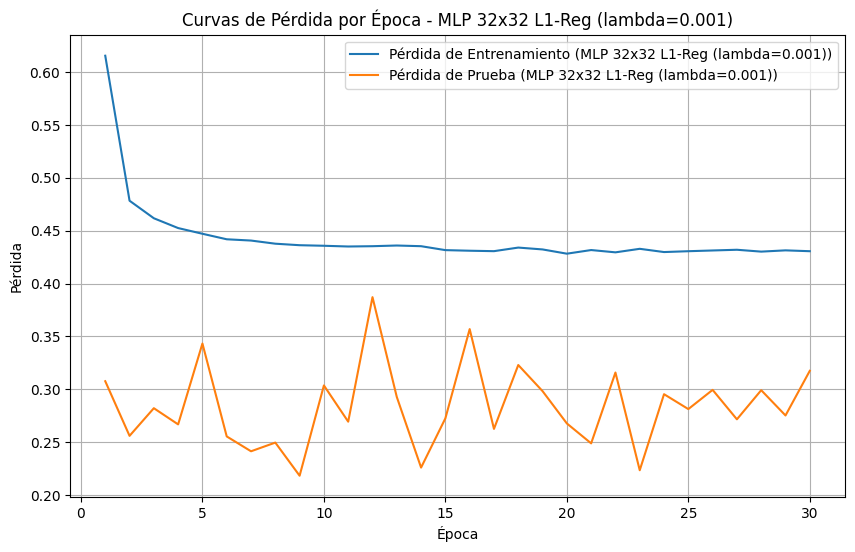


--- Experimentando con la arquitectura: MLP 32x32 L1-Reg (lambda=0.01) ---
Entrenando el modelo: MLP 32x32 L1-Reg (lambda=0.01) con 30 épocas y learning_rate=0.01...
Época 1/30, Pérdida de Entrenamiento: 1.3612, Pérdida de Prueba: 0.7005
Época 10/30, Pérdida de Entrenamiento: 1.2150, Pérdida de Prueba: 0.6093
Época 20/30, Pérdida de Entrenamiento: 1.2166, Pérdida de Prueba: 0.6714
Época 30/30, Pérdida de Entrenamiento: 1.2144, Pérdida de Prueba: 0.7502

Entrenamiento de MLP 32x32 L1-Reg (lambda=0.01) completado.

Evaluando el modelo MLP 32x32 L1-Reg (lambda=0.01) en el conjunto de prueba...
Evaluation Accuracy: 75.28%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.73      0.97      0.83      1381
           1       0.96      0.91      0.93      1575
           2       0.86      0.79      0.83      1398
           3       0.84      0.82      0.83      1428
           4       0.96      0.34      0.50      1365
           5       0.

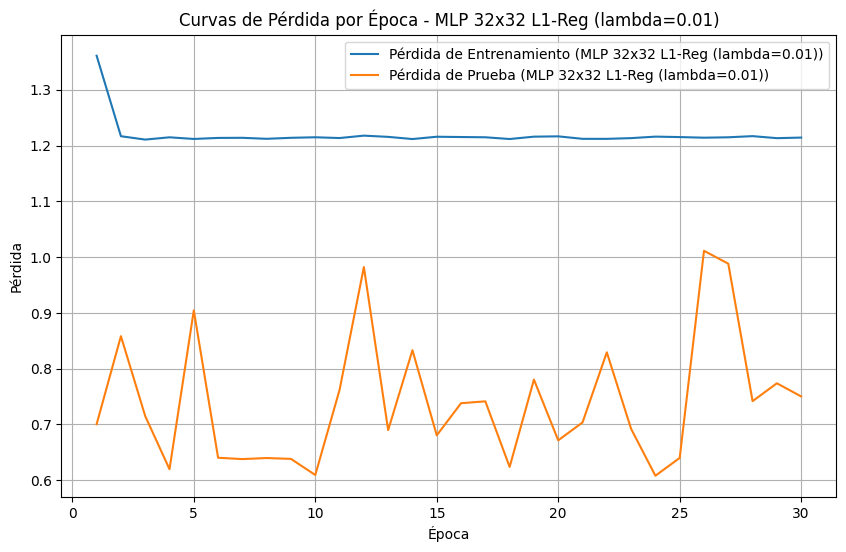


--- Experimentando con la arquitectura: MLP 32x32 L1-Reg (lambda=0.05) ---
Entrenando el modelo: MLP 32x32 L1-Reg (lambda=0.05) con 30 épocas y learning_rate=0.01...
Época 1/30, Pérdida de Entrenamiento: 2.5334, Pérdida de Prueba: 2.3027
Época 10/30, Pérdida de Entrenamiento: 2.4687, Pérdida de Prueba: 2.3020
Época 20/30, Pérdida de Entrenamiento: 2.4688, Pérdida de Prueba: 2.3035
Época 30/30, Pérdida de Entrenamiento: 2.4688, Pérdida de Prueba: 2.3031

Entrenamiento de MLP 32x32 L1-Reg (lambda=0.05) completado.

Evaluando el modelo MLP 32x32 L1-Reg (lambda=0.05) en el conjunto de prueba...
Evaluation Accuracy: 9.82%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1381
           1       0.00      0.00      0.00      1575
           2       0.00      0.00      0.00      1398
           3       0.00      0.00      0.00      1428
           4       0.00      0.00      0.00      1365
           5       0.0

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

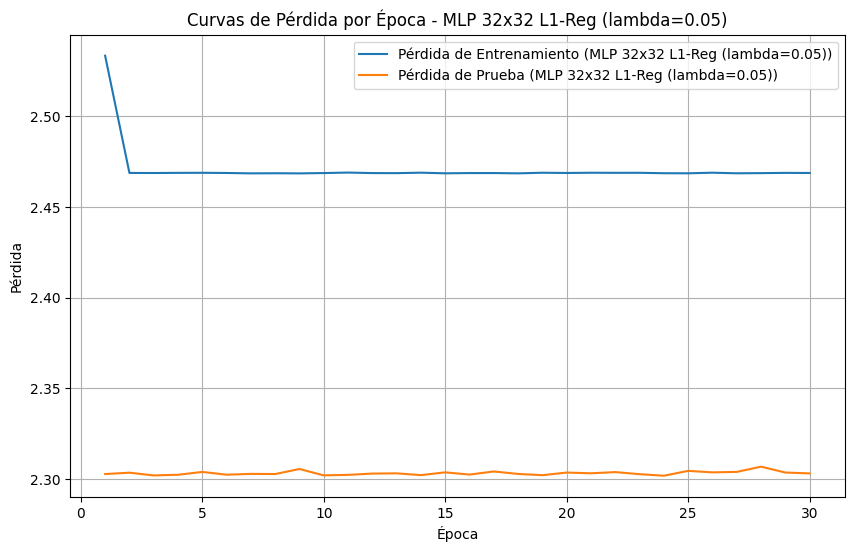


DataFrame de rendimiento final actualizado con L1:

                        Model Name  Accuracy  Precision (weighted)  \
0                   Base MLP Model  0.978500              0.978655   
1             Base MLP Model 32x32  0.965000              0.965129   
2                         MLP 2x64  0.973286              0.973383   
3                         MLP 3x32  0.965429              0.965578   
4    MLP 32x32 L1-Reg (lambda=0.1)  0.098214              0.009646   
5    MLP 32x32 L1-Reg (lambda=0.2)  0.097500              0.009506   
6  MLP 32x32 L1-Reg (lambda=0.001)  0.899500              0.904567   
7   MLP 32x32 L1-Reg (lambda=0.01)  0.752786              0.794416   
8   MLP 32x32 L1-Reg (lambda=0.05)  0.098214              0.009646   

   Recall (weighted)  F1-score (weighted)  Training Loss  Test Loss  
0           0.978500             0.978516       0.010729   0.144944  
1           0.965000             0.964930       0.056343   0.189396  
2           0.973286             0.9

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# --- Experimentación con Regularización L1 y diferentes lambdas ---

# Parámetros del modelo (arquitectura baseline)
input_size = X_train.shape[1] # 784 píxeles
hidden_layers_sizes = [32, 32] # Dos capas ocultas con 32 neuronas cada una
output_size = len(np.unique(y_train)) # 10 clases (0-9)

# Parámetros de entrenamiento
epochs = 30 # Número de épocas
learning_rate = 0.01 # Tasa de aprendizaje

# Valores de lambda para L1
lambda_l1_values = [0.001, 0.01, 0.05]

global model_performance_df # Acceder al DataFrame global

for lambda_l1 in lambda_l1_values:
    model_name = f'MLP {hidden_layers_sizes[0]}x{hidden_layers_sizes[1]} L1-Reg (lambda={lambda_l1})'
    print(f"\n--- Experimentando con la arquitectura: {model_name} ---")

    # Instanciar el modelo MLP con regularización L1 (usando la nueva clase MLP_L1)
    mlp_model_l1 = MLP_L1(input_size, hidden_layers_sizes, output_size, lambda_l1=lambda_l1)

    # Listas para almacenar la pérdida durante el entrenamiento y la evaluación en cada época
    train_losses_l1 = []
    test_losses_l1 = []

    print(f"Entrenando el modelo: {model_name} con {epochs} épocas y learning_rate={learning_rate}...")

    for epoch in range(epochs):
        # Mezcla los datos para el Descenso de Gradiente Estocástico (SGD)
        indices = np.arange(X_train.shape[0])
        np.random.shuffle(indices)
        X_shuffled = X_train[indices]
        y_shuffled_one_hot = y_train_one_hot[indices]

        epoch_train_loss = 0
        # Iterar sobre cada muestra para SGD (tamaño de "batch" de 1)
        for i in range(X_shuffled.shape[0]):
            x_sample = X_shuffled[i:i+1]
            y_sample = y_shuffled_one_hot[i:i+1]

            # Paso hacia adelante
            y_pred, cache = mlp_model_l1.forward(x_sample)
            loss = mlp_model_l1.compute_loss(y_sample, y_pred)
            epoch_train_loss += loss

            # Paso hacia atrás
            grads_W, grads_b = mlp_model_l1.backward(x_sample, y_sample, y_pred, cache)

            # Actualizar pesos y sesgos
            for j in range(len(mlp_model_l1.weights)):
                mlp_model_l1.weights[j] -= learning_rate * grads_W[j]
                mlp_model_l1.biases[j] -= learning_rate * grads_b[j]

        # Calcular la pérdida promedio de entrenamiento para la época
        avg_epoch_train_loss = epoch_train_loss / X_shuffled.shape[0]
        train_losses_l1.append(avg_epoch_train_loss)

        # Calcular la pérdida en el conjunto de prueba después de cada época
        y_test_pred_probs, _ = mlp_model_l1.forward(X_test)
        # Asegurarse de que compute_loss se llame con y_test_one_hot
        avg_epoch_test_loss = mlp_model_l1.compute_loss(y_test_one_hot, y_test_pred_probs)
        test_losses_l1.append(avg_epoch_test_loss)

        # Imprimir el progreso cada 10 épocas o al principio/final
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {avg_epoch_train_loss:.4f}, Pérdida de Prueba: {avg_epoch_test_loss:.4f}")

    print(f"\nEntrenamiento de {model_name} completado.\n")

    # 3. Evaluar el modelo en el conjunto de prueba
    print(f"Evaluando el modelo {model_name} en el conjunto de prueba...")
    accuracy = mlp_model_l1.evaluate(X_test, y_test)

    # Obtener predicciones para el reporte de clasificación
    y_pred_probs_test, _ = mlp_model_l1.forward(X_test)
    y_pred_classes_test = np.argmax(y_pred_probs_test, axis=1)

    # 4. Generar el Informe de Clasificación
    print("\nInforme de Clasificación:")
    report = classification_report(y_test, y_pred_classes_test, output_dict=True)
    print(classification_report(y_test, y_pred_classes_test))

    # 5. Graficar las Curvas de Pérdida
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, epochs + 1), train_losses_l1, label=f'Pérdida de Entrenamiento ({model_name})')
    plt.plot(range(1, epochs + 1), test_losses_l1, label=f'Pérdida de Prueba ({model_name})')
    plt.title(f'Curvas de Pérdida por Época - {model_name}')
    plt.xlabel('Época')
    plt.ylabel('Pérdida')
    plt.legend()
    plt.grid(True)
    plt.show()

    # 6. Almacenar Estadísticas en un DataFrame
    # Extraer métricas clave para el DataFrame
    accuracy_val = accuracy / 100.0 # Convertir de porcentaje a fracción
    precision_weighted = report['weighted avg']['precision']
    recall_weighted = report['weighted avg']['recall']
    f1_weighted = report['weighted avg']['f1-score']

    new_model_stats = pd.DataFrame([{
        'Model Name': model_name,
        'Accuracy': accuracy_val,
        'Precision (weighted)': precision_weighted,
        'Recall (weighted)': recall_weighted,
        'F1-score (weighted)': f1_weighted,
        'Training Loss': train_losses_l1[-1],
        'Test Loss': test_losses_l1[-1]
    }])

    model_performance_df = pd.concat([model_performance_df, new_model_stats], ignore_index=True)

print("\nDataFrame de rendimiento final actualizado con L1:\n")
print(model_performance_df)


## Experimento 3: Algortimos de optimización

El tercer experimento se enfoca en analizar el efecto del **algoritmo de optimización** utilizado durante el entrenamiento de la red neuronal. A diferencia de la regularización, cuya implementación puede realizarse directamente sobre la función de pérdida, la implementación desde cero de diferentes algoritmos de optimización requiere manejar mecanismos adicionales relacionados con la actualización de los parámetros. Por esta razón, en este experimento se utilizarán las implementaciones proporcionadas por **scikit-learn**, permitiendo concentrar el análisis en el comportamiento de los diferentes optimizadores.

Como punto de referencia se mantendrá el optimizador utilizado por el modelo baseline, correspondiente al **gradiente descendente estándar**. A partir de este se realizarán dos pruebas adicionales: **gradiente descendente con momentum** y **Adam**. De esta manera, se podrá comparar el comportamiento del entrenamiento manteniendo el resto de la arquitectura y las condiciones del modelo lo más constantes posible.

El objetivo principal es analizar cómo estos métodos modifican la forma en que la red actualiza sus parámetros durante el aprendizaje. En particular, se busca observar el impacto que tienen sobre el **learning rate** y sobre la magnitud y dirección de las actualizaciones producidas por los gradientes a lo largo del entrenamiento. El uso de momentum permite incorporar información de actualizaciones anteriores para modificar el comportamiento del descenso, mientras que Adam incorpora mecanismos adaptativos para ajustar el tamaño de las actualizaciones de los diferentes parámetros.

Por lo tanto, el tercer experimento estará enfocado exclusivamente en comparar los **optimizadores**, evaluando cómo cada estrategia afecta la velocidad y estabilidad del aprendizaje y la convergencia del modelo. El modelo baseline funcionará como referencia para determinar qué diferencias aparecen al incorporar momentum y Adam en el proceso de entrenamiento.



--- Experimentando con la arquitectura: MLP 32x32 SGD (Batch) --- 
Entrenando el modelo: MLP 32x32 SGD (Batch) con 30 épocas, learning_rate=0.01 y batch_size=32...
Época 1/30, Pérdida de Entrenamiento: 0.6884, Pérdida de Prueba: 0.3540
Época 10/30, Pérdida de Entrenamiento: 0.1451, Pérdida de Prueba: 0.1675
Época 20/30, Pérdida de Entrenamiento: 0.0941, Pérdida de Prueba: 0.1295
Época 30/30, Pérdida de Entrenamiento: 0.0698, Pérdida de Prueba: 0.1171

Entrenamiento de MLP 32x32 SGD (Batch) completado.

Evaluando el modelo MLP 32x32 SGD (Batch) en el conjunto de prueba...
Evaluation Accuracy: 96.64%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1381
           1       0.97      0.99      0.98      1575
           2       0.96      0.96      0.96      1398
           3       0.96      0.95      0.95      1428
           4       0.97      0.96      0.96      1365
           5       0.97      0.95      0.

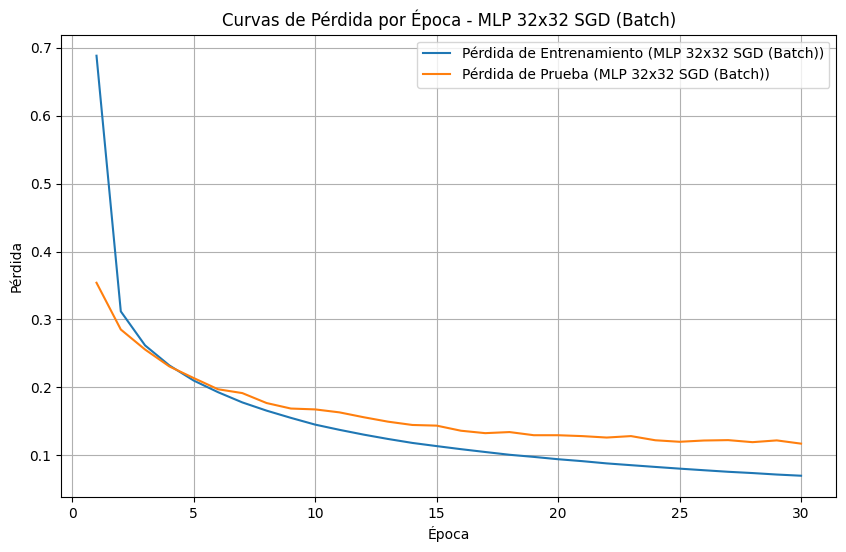


--- Experimentando con la arquitectura: MLP 32x32 Momentum --- 
Entrenando el modelo: MLP 32x32 Momentum con 30 épocas, learning_rate=0.01 y batch_size=32...
Época 1/30, Pérdida de Entrenamiento: 0.3336, Pérdida de Prueba: 0.2082
Época 10/30, Pérdida de Entrenamiento: 0.0698, Pérdida de Prueba: 0.1196
Época 20/30, Pérdida de Entrenamiento: 0.0404, Pérdida de Prueba: 0.1479
Época 30/30, Pérdida de Entrenamiento: 0.0280, Pérdida de Prueba: 0.1617

Entrenamiento de MLP 32x32 Momentum completado.

Evaluando el modelo MLP 32x32 Momentum en el conjunto de prueba...
Evaluation Accuracy: 96.59%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1381
           1       0.98      0.98      0.98      1575
           2       0.95      0.98      0.96      1398
           3       0.96      0.95      0.95      1428
           4       0.96      0.97      0.97      1365
           5       0.94      0.97      0.95      1263

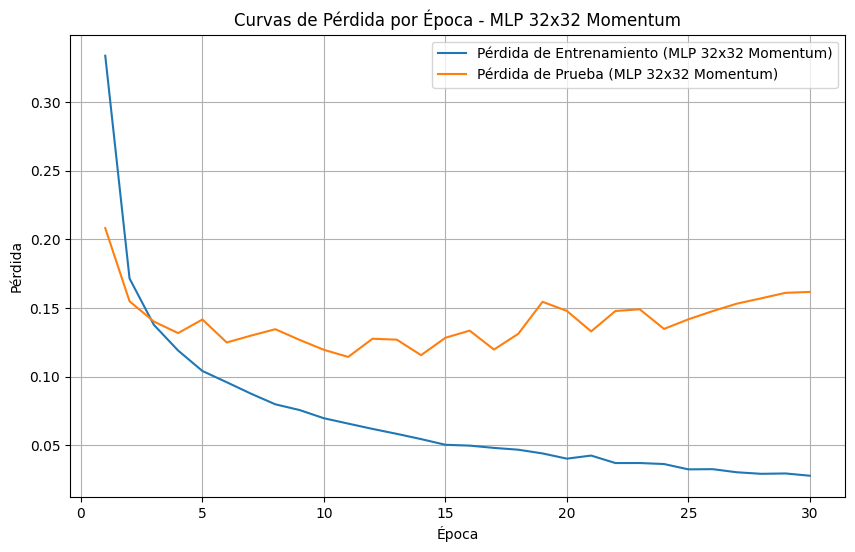


--- Experimentando con la arquitectura: MLP 32x32 Adam --- 
Entrenando el modelo: MLP 32x32 Adam con 30 épocas, learning_rate=0.01 y batch_size=32...
Época 1/30, Pérdida de Entrenamiento: 0.2762, Pérdida de Prueba: 0.2017
Época 10/30, Pérdida de Entrenamiento: 0.0787, Pérdida de Prueba: 0.1465
Época 20/30, Pérdida de Entrenamiento: 0.0567, Pérdida de Prueba: 0.1674
Época 30/30, Pérdida de Entrenamiento: 0.0494, Pérdida de Prueba: 0.2010

Entrenamiento de MLP 32x32 Adam completado.

Evaluando el modelo MLP 32x32 Adam en el conjunto de prueba...
Evaluation Accuracy: 95.68%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1381
           1       0.98      0.98      0.98      1575
           2       0.97      0.94      0.96      1398
           3       0.91      0.96      0.94      1428
           4       0.95      0.95      0.95      1365
           5       0.96      0.92      0.94      1263
           6   

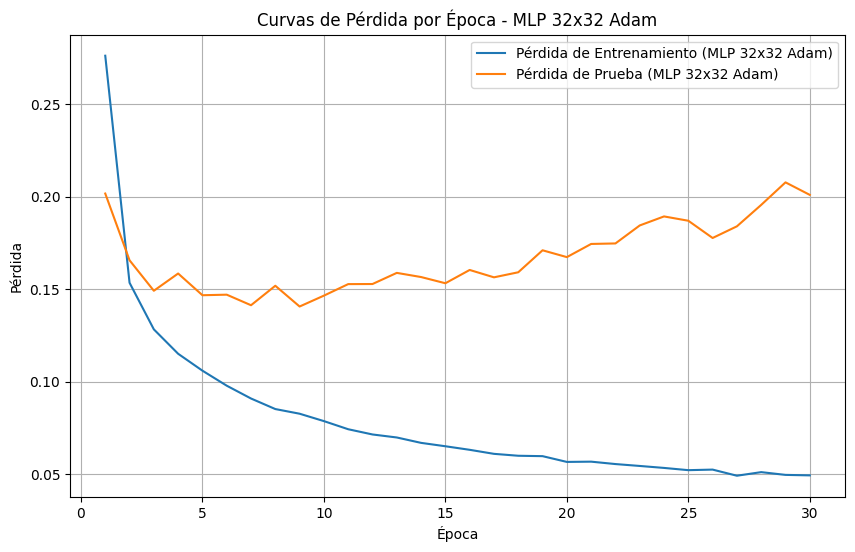


DataFrame de rendimiento final actualizado con optimizadores:

                         Model Name  Accuracy  Precision (weighted)  \
0                    Base MLP Model  0.978500              0.978655   
1              Base MLP Model 32x32  0.965000              0.965129   
2                          MLP 2x64  0.973286              0.973383   
3                          MLP 3x32  0.965429              0.965578   
4     MLP 32x32 L1-Reg (lambda=0.1)  0.098214              0.009646   
5     MLP 32x32 L1-Reg (lambda=0.2)  0.097500              0.009506   
6   MLP 32x32 L1-Reg (lambda=0.001)  0.899500              0.904567   
7    MLP 32x32 L1-Reg (lambda=0.01)  0.752786              0.794416   
8    MLP 32x32 L1-Reg (lambda=0.05)  0.098214              0.009646   
9             MLP 32x32 SGD (Batch)  0.966357              0.966380   
10               MLP 32x32 Momentum  0.965857              0.965983   
11                   MLP 32x32 Adam  0.956786              0.957162   

    Recall (

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

def train_and_evaluate_mlp_optimizers(
    hidden_layers_sizes,
    epochs,
    learning_rate,
    optimizer_type,
    batch_size,
    momentum_beta,
    adam_beta1,
    adam_beta2,
    adam_epsilon,
    model_name,
    X_train,
    y_train,
    X_test,
    y_test,
    output_size,
    y_train_one_hot,
    y_test_one_hot,
    model_performance_df_global
):
    print(f"\n--- Experimentando con la arquitectura: {model_name} --- ")
    input_size = X_train.shape[1]

    # Instantiate the new MLP_Optimizers class
    mlp_model = MLP_Optimizers(
        input_size, hidden_layers_sizes, output_size,
        optimizer_type=optimizer_type, batch_size=batch_size,
        momentum_beta=momentum_beta, adam_beta1=adam_beta1,
        adam_beta2=adam_beta2, adam_epsilon=adam_epsilon
    )

    print(f"Entrenando el modelo: {model_name} con {epochs} épocas, learning_rate={learning_rate} y batch_size={batch_size}...")

    # The train method of MLP_Optimizers now returns the losses
    train_losses, test_losses = mlp_model.train(X_train, y_train, epochs, learning_rate)

    # Manually print progress for consistency as the train method no longer prints
    for epoch in range(epochs):
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {train_losses[epoch]:.4f}, Pérdida de Prueba: {test_losses[epoch]:.4f}")

    print(f"\nEntrenamiento de {model_name} completado.\n")

    print(f"Evaluando el modelo {model_name} en el conjunto de prueba...")
    accuracy = mlp_model.evaluate(X_test, y_test)

    y_pred_probs_test, _ = mlp_model.forward(X_test)
    y_pred_classes_test = np.argmax(y_pred_probs_test, axis=1)

    print("\nInforme de Clasificación:")
    report = classification_report(y_test, y_pred_classes_test, output_dict=True)
    print(classification_report(y_test, y_pred_classes_test))

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, epochs + 1), train_losses, label=f'Pérdida de Entrenamiento ({model_name})')
    plt.plot(range(1, epochs + 1), test_losses, label=f'Pérdida de Prueba ({model_name})')
    plt.title(f'Curvas de Pérdida por Época - {model_name}')
    plt.xlabel('Época')
    plt.ylabel('Pérdida')
    plt.legend()
    plt.grid(True)
    plt.show()

    accuracy_val = accuracy / 100.0
    precision_weighted = report['weighted avg']['precision']
    recall_weighted = report['weighted avg']['recall']
    f1_weighted = report['weighted avg']['f1-score']

    new_model_stats = pd.DataFrame([{
        'Model Name': model_name,
        'Accuracy': accuracy_val,
        'Precision (weighted)': precision_weighted,
        'Recall (weighted)': recall_weighted,
        'F1-score (weighted)': f1_weighted,
        'Training Loss': train_losses[-1],
        'Test Loss': test_losses[-1]
    }])

    return pd.concat([model_performance_df_global, new_model_stats], ignore_index=True)

# --- Ejecutar Experimentos con Optimizadores ---

common_epochs = 30
common_learning_rate = 0.01
common_batch_size = 32

# Arquitectura baseline 32x32
optimizer_hidden_layers = [32, 32]

# 1. Experimento con SGD (usando mini-batches para consistencia con la nueva clase)
model_performance_df = train_and_evaluate_mlp_optimizers(
    optimizer_hidden_layers,
    common_epochs,
    common_learning_rate,
    optimizer_type='sgd',
    batch_size=common_batch_size,
    momentum_beta=0.0,
    adam_beta1=0.0,
    adam_beta2=0.0,
    adam_epsilon=0.0,
    model_name='MLP 32x32 SGD (Batch)',
    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
    output_size=output_size, y_train_one_hot=y_train_one_hot, y_test_one_hot=y_test_one_hot,
    model_performance_df_global=model_performance_df
)

# 2. Experimento con Momentum
model_performance_df = train_and_evaluate_mlp_optimizers(
    optimizer_hidden_layers,
    common_epochs,
    common_learning_rate,
    optimizer_type='momentum',
    batch_size=common_batch_size,
    momentum_beta=0.9, # Hyperparameter for Momentum
    adam_beta1=0.0,
    adam_beta2=0.0,
    adam_epsilon=0.0,
    model_name='MLP 32x32 Momentum',
    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
    output_size=output_size, y_train_one_hot=y_train_one_hot, y_test_one_hot=y_test_one_hot,
    model_performance_df_global=model_performance_df
)

# 3. Experimento con Adam
model_performance_df = train_and_evaluate_mlp_optimizers(
    optimizer_hidden_layers,
    common_epochs,
    common_learning_rate,
    optimizer_type='adam',
    batch_size=common_batch_size,
    momentum_beta=0.0,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8, # Hyperparameters for Adam
    model_name='MLP 32x32 Adam',
    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
    output_size=output_size, y_train_one_hot=y_train_one_hot, y_test_one_hot=y_test_one_hot,
    model_performance_df_global=model_performance_df
)

print("\nDataFrame de rendimiento final actualizado con optimizadores:\n")
print(model_performance_df)


## Experimento 4: Técnicas combinadas


--- Experimentando con la arquitectura: MLP 64x64 Sgd --- 
Entrenando el modelo: MLP 64x64 Sgd con 30 épocas, learning_rate=0.01, batch_size=32, reg_type=none, lambda=0.0...
Época 1/30, Pérdida de Entrenamiento: 0.6336, Pérdida de Prueba: 0.3260
Época 10/30, Pérdida de Entrenamiento: 0.1217, Pérdida de Prueba: 0.1436
Época 20/30, Pérdida de Entrenamiento: 0.0705, Pérdida de Prueba: 0.1054
Época 30/30, Pérdida de Entrenamiento: 0.0470, Pérdida de Prueba: 0.0925

Entrenamiento de MLP 64x64 Sgd completado.

Evaluando el modelo MLP 64x64 Sgd en el conjunto de prueba...
Evaluation Accuracy: 97.33%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1381
           1       0.98      0.99      0.98      1575
           2       0.98      0.97      0.97      1398
           3       0.95      0.97      0.96      1428
           4       0.98      0.97      0.97      1365
           5       0.98      0.96      0.97    

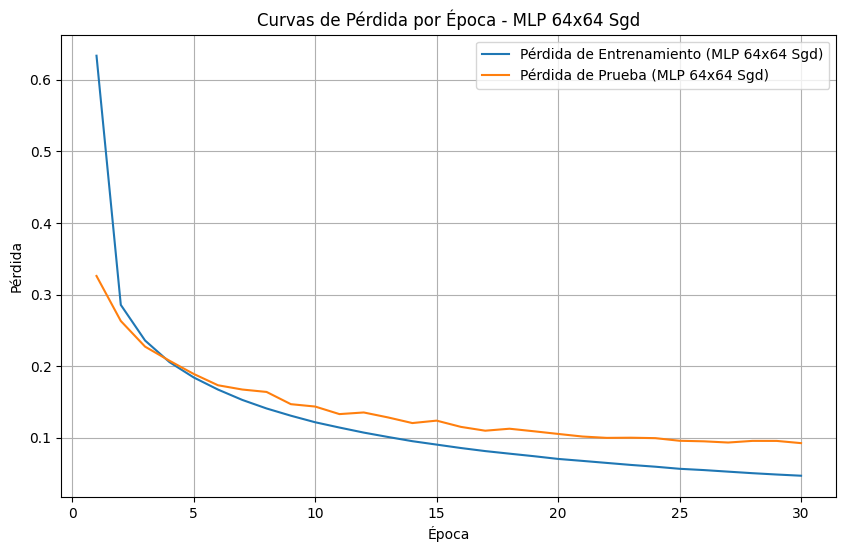


--- Experimentando con la arquitectura: MLP 64x64 Momentum --- 
Entrenando el modelo: MLP 64x64 Momentum con 30 épocas, learning_rate=0.01, batch_size=32, reg_type=none, lambda=0.0...
Época 1/30, Pérdida de Entrenamiento: 0.2876, Pérdida de Prueba: 0.1687
Época 10/30, Pérdida de Entrenamiento: 0.0305, Pérdida de Prueba: 0.0991
Época 20/30, Pérdida de Entrenamiento: 0.0034, Pérdida de Prueba: 0.0958
Época 30/30, Pérdida de Entrenamiento: 0.0005, Pérdida de Prueba: 0.1055

Entrenamiento de MLP 64x64 Momentum completado.

Evaluando el modelo MLP 64x64 Momentum en el conjunto de prueba...
Evaluation Accuracy: 97.87%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1381
           1       0.98      0.99      0.99      1575
           2       0.98      0.98      0.98      1398
           3       0.98      0.97      0.98      1428
           4       0.98      0.97      0.97      1365
           5       0.98    

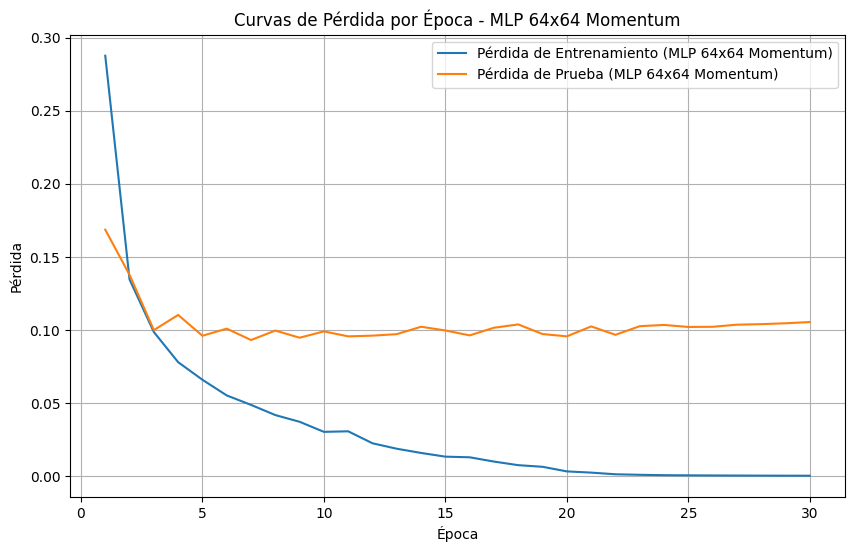


--- Experimentando con la arquitectura: MLP 64x64 Adam --- 
Entrenando el modelo: MLP 64x64 Adam con 30 épocas, learning_rate=0.01, batch_size=32, reg_type=none, lambda=0.0...
Época 1/30, Pérdida de Entrenamiento: 0.2290, Pérdida de Prueba: 0.1507
Época 10/30, Pérdida de Entrenamiento: 0.0274, Pérdida de Prueba: 0.1212
Época 20/30, Pérdida de Entrenamiento: 0.0165, Pérdida de Prueba: 0.1668
Época 30/30, Pérdida de Entrenamiento: 0.0155, Pérdida de Prueba: 0.2171

Entrenamiento de MLP 64x64 Adam completado.

Evaluando el modelo MLP 64x64 Adam en el conjunto de prueba...
Evaluation Accuracy: 96.91%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1381
           1       0.98      0.99      0.98      1575
           2       0.97      0.97      0.97      1398
           3       0.98      0.95      0.96      1428
           4       0.98      0.95      0.97      1365
           5       0.97      0.96      0.96

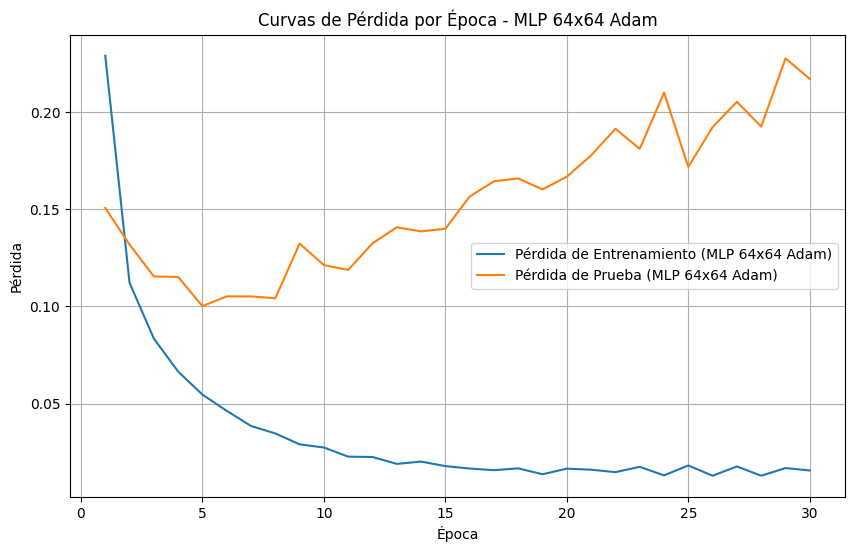


--- Experimentando con la arquitectura: MLP 64x64 Sgd L2 (lambda=0.01) --- 
Entrenando el modelo: MLP 64x64 Sgd L2 (lambda=0.01) con 30 épocas, learning_rate=0.01, batch_size=32, reg_type=l2, lambda=0.01...
Época 1/30, Pérdida de Entrenamiento: 0.6769, Pérdida de Prueba: 0.3265
Época 10/30, Pérdida de Entrenamiento: 0.1756, Pérdida de Prueba: 0.1396
Época 20/30, Pérdida de Entrenamiento: 0.1277, Pérdida de Prueba: 0.1037
Época 30/30, Pérdida de Entrenamiento: 0.1060, Pérdida de Prueba: 0.0927

Entrenamiento de MLP 64x64 Sgd L2 (lambda=0.01) completado.

Evaluando el modelo MLP 64x64 Sgd L2 (lambda=0.01) en el conjunto de prueba...
Evaluation Accuracy: 97.23%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1381
           1       0.98      0.99      0.98      1575
           2       0.97      0.97      0.97      1398
           3       0.95      0.97      0.96      1428
           4       0.97      0.97 

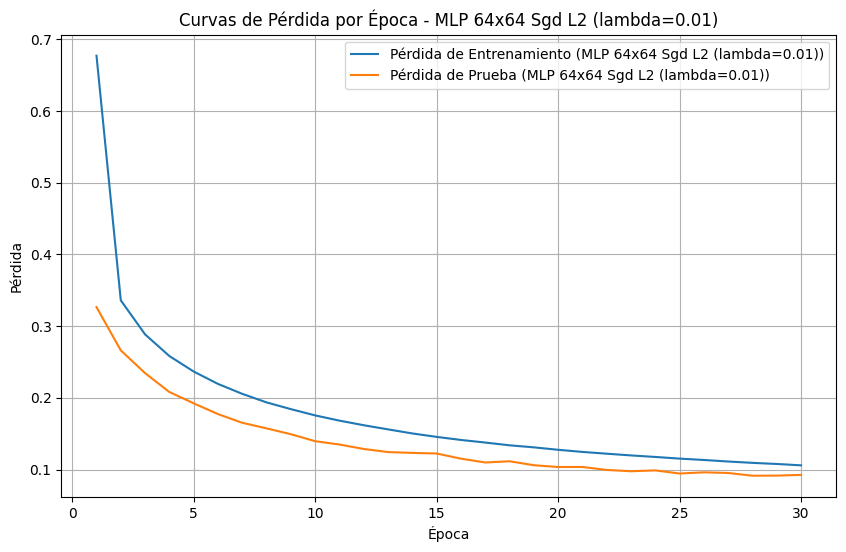


--- Experimentando con la arquitectura: MLP 64x64 Momentum L2 (lambda=0.01) --- 
Entrenando el modelo: MLP 64x64 Momentum L2 (lambda=0.01) con 30 épocas, learning_rate=0.01, batch_size=32, reg_type=l2, lambda=0.01...
Época 1/30, Pérdida de Entrenamiento: 0.3431, Pérdida de Prueba: 0.1848
Época 10/30, Pérdida de Entrenamiento: 0.0957, Pérdida de Prueba: 0.0890
Época 20/30, Pérdida de Entrenamiento: 0.0763, Pérdida de Prueba: 0.0844
Época 30/30, Pérdida de Entrenamiento: 0.0691, Pérdida de Prueba: 0.0810

Entrenamiento de MLP 64x64 Momentum L2 (lambda=0.01) completado.

Evaluando el modelo MLP 64x64 Momentum L2 (lambda=0.01) en el conjunto de prueba...
Evaluation Accuracy: 97.45%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1381
           1       0.98      0.99      0.99      1575
           2       0.98      0.96      0.97      1398
           3       0.98      0.96      0.97      1428
           4  

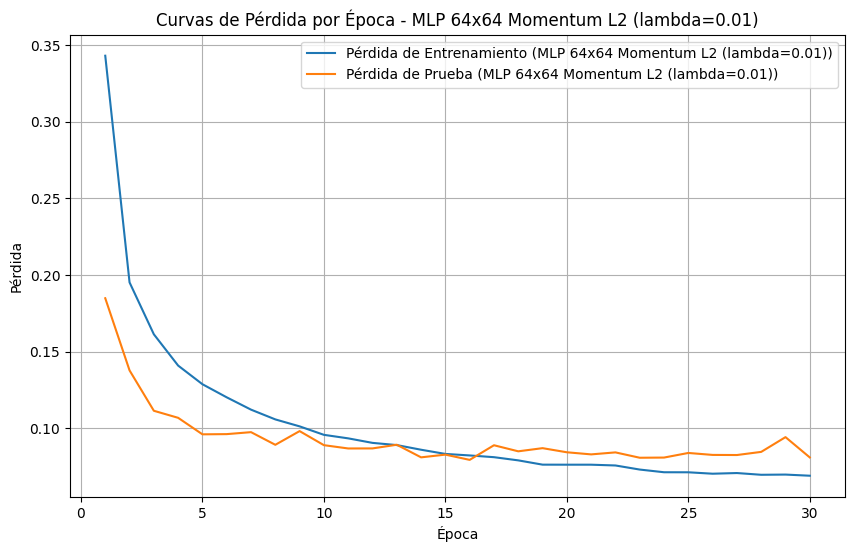


--- Experimentando con la arquitectura: MLP 64x64 Adam L2 (lambda=0.01) --- 
Entrenando el modelo: MLP 64x64 Adam L2 (lambda=0.01) con 30 épocas, learning_rate=0.01, batch_size=32, reg_type=l2, lambda=0.01...
Época 1/30, Pérdida de Entrenamiento: 0.3110, Pérdida de Prueba: 0.1731
Época 10/30, Pérdida de Entrenamiento: 0.1179, Pérdida de Prueba: 0.0900
Época 20/30, Pérdida de Entrenamiento: 0.1135, Pérdida de Prueba: 0.1021
Época 30/30, Pérdida de Entrenamiento: 0.1135, Pérdida de Prueba: 0.0977

Entrenamiento de MLP 64x64 Adam L2 (lambda=0.01) completado.

Evaluando el modelo MLP 64x64 Adam L2 (lambda=0.01) en el conjunto de prueba...
Evaluation Accuracy: 97.01%

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1381
           1       0.97      0.99      0.98      1575
           2       0.98      0.97      0.97      1398
           3       0.96      0.97      0.96      1428
           4       0.97      0

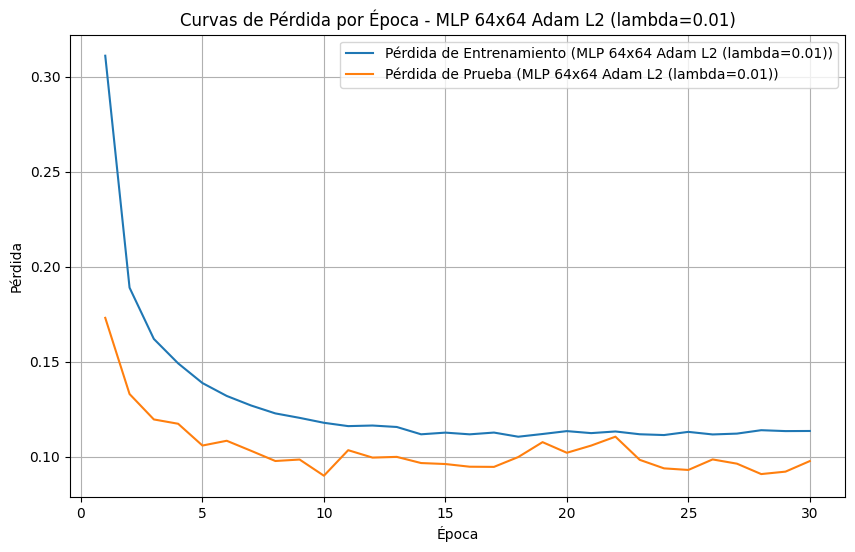


DataFrame de rendimiento final actualizado con todas las combinaciones:

                             Model Name  Accuracy  Precision (weighted)  \
0                        Base MLP Model  0.978500              0.978655   
1                  Base MLP Model 32x32  0.965000              0.965129   
2                              MLP 2x64  0.973286              0.973383   
3                              MLP 3x32  0.965429              0.965578   
4         MLP 32x32 L1-Reg (lambda=0.1)  0.098214              0.009646   
5         MLP 32x32 L1-Reg (lambda=0.2)  0.097500              0.009506   
6       MLP 32x32 L1-Reg (lambda=0.001)  0.899500              0.904567   
7        MLP 32x32 L1-Reg (lambda=0.01)  0.752786              0.794416   
8        MLP 32x32 L1-Reg (lambda=0.05)  0.098214              0.009646   
9                 MLP 32x32 SGD (Batch)  0.966357              0.966380   
10                   MLP 32x32 Momentum  0.965857              0.965983   
11                       M

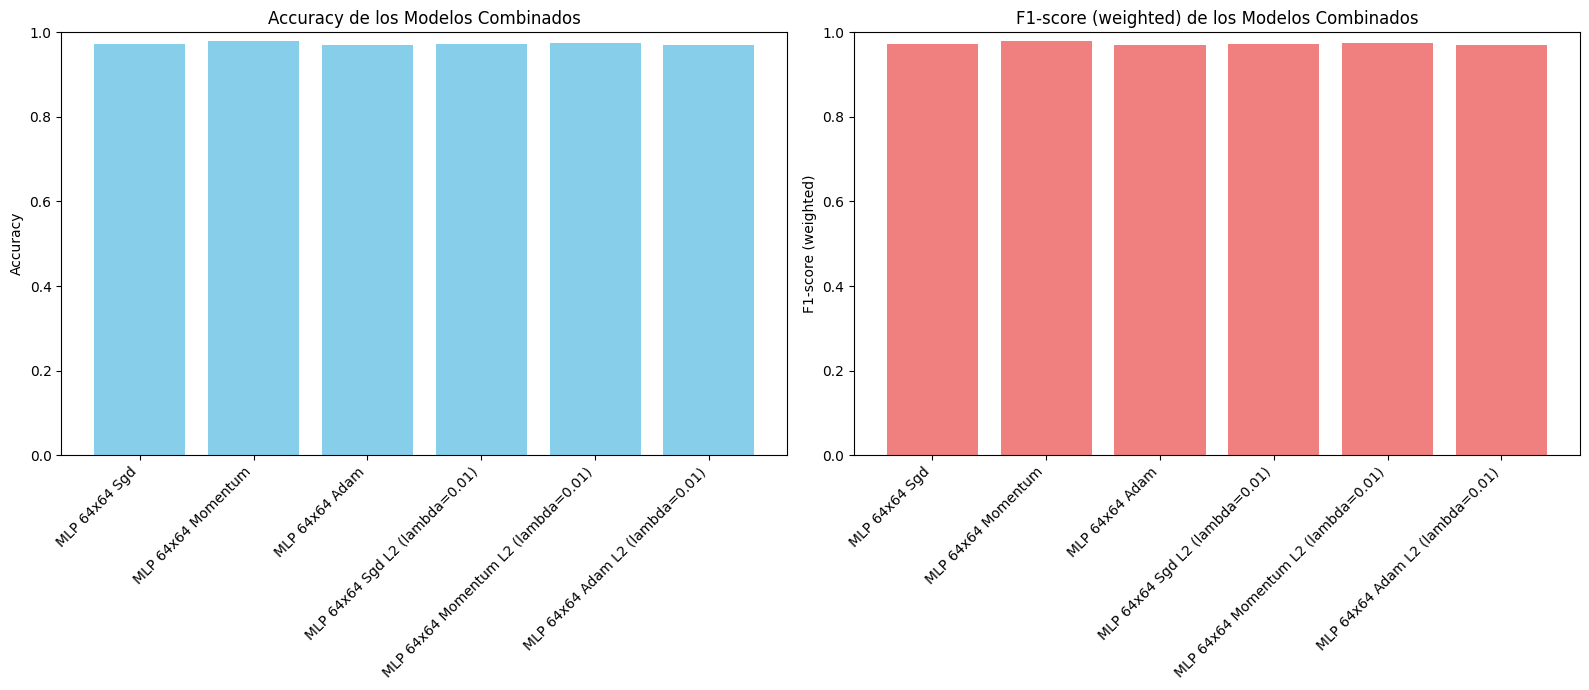

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Nueva clase MLP_Combined que integra optimizadores y regularización
class MLP_Combined:
    def __init__(self, input_size, hidden_layers_sizes, output_size,
                 optimizer_type='sgd', batch_size=32,
                 momentum_beta=0.9, adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-8,
                 regularization_type='none', lambda_reg=0.0):
        self.input_size = input_size
        self.hidden_layers_sizes = hidden_layers_sizes
        self.output_size = output_size
        self.optimizer_type = optimizer_type
        self.batch_size = batch_size
        self.momentum_beta = momentum_beta
        self.adam_beta1 = adam_beta1
        self.adam_beta2 = adam_beta2
        self.adam_epsilon = adam_epsilon
        self.regularization_type = regularization_type
        self.lambda_reg = lambda_reg

        self.weights = []
        self.biases = []
        self.activations = []

        layer_sizes = [input_size] + hidden_layers_sizes + [output_size]

        for i in range(len(layer_sizes) - 1):
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2. / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1]))
            self.weights.append(w)
            self.biases.append(b)

            if i < len(layer_sizes) - 2:
                self.activations.append(self.relu)
            else:
                self.activations.append(self.softmax)

        # Inicializar parámetros específicos del optimizador
        if self.optimizer_type == 'momentum':
            self.v_weights = [np.zeros_like(w) for w in self.weights]
            self.v_biases = [np.zeros_like(b) for b in self.biases]
        elif self.optimizer_type == 'adam':
            self.m_weights = [np.zeros_like(w) for w in self.weights]
            self.v_weights_adam = [np.zeros_like(w) for w in self.weights]
            self.m_biases = [np.zeros_like(b) for b in self.biases]
            self.v_biases_adam = [np.zeros_like(b) for b in self.biases]
            self.t = 0 # Contador para la corrección de sesgo en Adam

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def softmax(self, x):
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        if X.ndim == 1:
            X = X.reshape(1, -1)
        A = X
        activations_cache = [A]
        Z_cache = []

        for i in range(len(self.weights)):
            W = self.weights[i]
            b = self.biases[i]
            activation_func = self.activations[i]

            Z = np.dot(A, W) + b
            A = activation_func(Z)

            Z_cache.append(Z)
            activations_cache.append(A)
        return A, {'Z': Z_cache, 'A': activations_cache}

    def compute_loss(self, y_true, y_pred):
        y_pred = np.clip(y_pred, 1e-10, 1 - 1e-10)
        loss = -np.sum(y_true * np.log(y_pred)) / y_true.shape[0]

        # Añadir término de regularización si lambda_reg > 0
        if self.lambda_reg > 0:
            reg_penalty = 0
            if self.regularization_type == 'l1':
                for w in self.weights:
                    reg_penalty += np.sum(np.abs(w))
                loss += (self.lambda_reg / (2 * y_true.shape[0])) * reg_penalty
            elif self.regularization_type == 'l2':
                for w in self.weights:
                    reg_penalty += np.sum(w**2)
                # Dividir por 2 para que la derivada sea más sencilla (lambda/m * W)
                loss += (self.lambda_reg / (2 * y_true.shape[0])) * reg_penalty

        return loss

    def backward(self, X, y_true, y_pred, cache):
        grads_W = [np.zeros_like(w) for w in self.weights]
        grads_b = [np.zeros_like(b) for b in self.biases]
        m = X.shape[0]

        A_cache = cache['A']
        Z_cache = cache['Z']

        dZ = (y_pred - y_true) / m

        grads_W[-1] = np.dot(A_cache[-2].T, dZ)
        grads_b[-1] = np.sum(dZ, axis=0, keepdims=True)

        # Añadir gradiente de regularización a la capa de salida
        if self.lambda_reg > 0:
            if self.regularization_type == 'l1':
                grads_W[-1] += (self.lambda_reg / m) * np.sign(self.weights[-1])
            elif self.regularization_type == 'l2':
                grads_W[-1] += (self.lambda_reg / m) * self.weights[-1]

        for i in reversed(range(len(self.weights) - 1)):
            W_current = self.weights[i+1]
            Z_current = Z_cache[i] # Z para la capa oculta actual

            dA_prev = np.dot(dZ, W_current.T)
            dZ = dA_prev * self.relu_derivative(Z_current)

            grads_W[i] = np.dot(A_cache[i].T, dZ)
            grads_b[i] = np.sum(dZ, axis=0, keepdims=True)

            # Añadir gradiente de regularización a las capas ocultas
            if self.lambda_reg > 0:
                if self.regularization_type == 'l1':
                    grads_W[i] += (self.lambda_reg / m) * np.sign(self.weights[i])
                elif self.regularization_type == 'l2':
                    grads_W[i] += (self.lambda_reg / m) * self.weights[i]

        return grads_W, grads_b

    def train(self, X_train, y_train, epochs, learning_rate):
        if y_train.ndim == 1:
            y_train_one_hot = np.eye(self.output_size)[y_train]
        else:
            y_train_one_hot = y_train

        num_samples = X_train.shape[0]
        num_batches = int(np.ceil(num_samples / self.batch_size))

        train_losses = []
        test_losses = []

        for epoch in range(epochs):
            indices = np.arange(num_samples)
            np.random.shuffle(indices)

            epoch_train_loss = 0
            if self.optimizer_type == 'adam':
                self.t += 1 # Increment time step for Adam bias correction

            for batch_idx in range(num_batches):
                start = batch_idx * self.batch_size
                end = min((batch_idx + 1) * self.batch_size, num_samples)
                batch_indices = indices[start:end]

                X_batch = X_train[batch_indices]
                y_batch_one_hot = y_train_one_hot[batch_indices]

                y_pred, cache = self.forward(X_batch)
                loss = self.compute_loss(y_batch_one_hot, y_pred)
                epoch_train_loss += loss * X_batch.shape[0] # Accumulate total loss for average

                grads_W, grads_b = self.backward(X_batch, y_batch_one_hot, y_pred, cache)

                for j in range(len(self.weights)):
                    if self.optimizer_type == 'sgd':
                        self.weights[j] -= learning_rate * grads_W[j]
                        self.biases[j] -= learning_rate * grads_b[j]
                    elif self.optimizer_type == 'momentum':
                        self.v_weights[j] = self.momentum_beta * self.v_weights[j] - learning_rate * grads_W[j]
                        self.v_biases[j] = self.momentum_beta * self.v_biases[j] - learning_rate * grads_b[j]
                        self.weights[j] += self.v_weights[j]
                        self.biases[j] += self.v_biases[j]
                    elif self.optimizer_type == 'adam':
                        # Update biased first moment estimate
                        self.m_weights[j] = self.adam_beta1 * self.m_weights[j] + (1 - self.adam_beta1) * grads_W[j]
                        self.m_biases[j] = self.adam_beta1 * self.m_biases[j] + (1 - self.adam_beta1) * grads_b[j]

                        # Update biased second raw moment estimate
                        self.v_weights_adam[j] = self.adam_beta2 * self.v_weights_adam[j] + (1 - self.adam_beta2) * (grads_W[j] ** 2)
                        self.v_biases_adam[j] = self.adam_beta2 * self.v_biases_adam[j] + (1 - self.adam_beta2) * (grads_b[j] ** 2)

                        # Compute bias-corrected first moment estimate
                        m_hat_W = self.m_weights[j] / (1 - self.adam_beta1 ** self.t)
                        m_hat_b = self.m_biases[j] / (1 - self.adam_beta1 ** self.t)

                        # Compute bias-corrected second raw moment estimate
                        v_hat_W = self.v_weights_adam[j] / (1 - self.adam_beta2 ** self.t)
                        v_hat_b = self.v_biases_adam[j] / (1 - self.adam_beta2 ** self.t)

                        # Update weights and biases
                        self.weights[j] -= learning_rate * m_hat_W / (np.sqrt(v_hat_W) + self.adam_epsilon)
                        self.biases[j] -= learning_rate * m_hat_b / (np.sqrt(v_hat_b) + self.adam_epsilon)

            # Calculate average epoch loss for train set
            avg_epoch_train_loss = epoch_train_loss / num_samples
            train_losses.append(avg_epoch_train_loss)

            # Calculate loss on test set after each epoch
            y_test_pred_probs, _ = self.forward(X_test)
            avg_epoch_test_loss = self.compute_loss(y_test_one_hot, y_test_pred_probs)
            test_losses.append(avg_epoch_test_loss)

            # Print progress only if called from the helper function
            # if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
            #     print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {avg_epoch_train_loss:.4f}, Pérdida de Prueba: {avg_epoch_test_loss:.4f}")

        return train_losses, test_losses

    def evaluate(self, X_test, y_test):
        y_pred_probs, _ = self.forward(X_test)
        y_pred_classes = np.argmax(y_pred_probs, axis=1)

        accuracy = np.mean(y_pred_classes == y_test) * 100
        print(f"Evaluation Accuracy: {accuracy:.2f}%")
        return accuracy

def train_and_evaluate_mlp_combined(
    hidden_layers_sizes,
    epochs,
    learning_rate,
    optimizer_type,
    batch_size,
    momentum_beta,
    adam_beta1,
    adam_beta2,
    adam_epsilon,
    regularization_type,
    lambda_reg,
    model_name,
    X_train,
    y_train,
    X_test,
    y_test,
    output_size,
    y_train_one_hot,
    y_test_one_hot,
    model_performance_df_global
):
    print(f"\n--- Experimentando con la arquitectura: {model_name} --- ")
    input_size = X_train.shape[1]

    mlp_model = MLP_Combined(
        input_size, hidden_layers_sizes, output_size,
        optimizer_type=optimizer_type, batch_size=batch_size,
        momentum_beta=momentum_beta, adam_beta1=adam_beta1,
        adam_beta2=adam_beta2, adam_epsilon=adam_epsilon,
        regularization_type=regularization_type, lambda_reg=lambda_reg
    )

    print(f"Entrenando el modelo: {model_name} con {epochs} épocas, learning_rate={learning_rate}, batch_size={batch_size}, reg_type={regularization_type}, lambda={lambda_reg}...")

    train_losses, test_losses = mlp_model.train(X_train, y_train, epochs, learning_rate)

    for epoch in range(epochs):
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"Época {epoch+1}/{epochs}, Pérdida de Entrenamiento: {train_losses[epoch]:.4f}, Pérdida de Prueba: {test_losses[epoch]:.4f}")

    print(f"\nEntrenamiento de {model_name} completado.\n")

    print(f"Evaluando el modelo {model_name} en el conjunto de prueba...")
    accuracy = mlp_model.evaluate(X_test, y_test)

    y_pred_probs_test, _ = mlp_model.forward(X_test)
    y_pred_classes_test = np.argmax(y_pred_probs_test, axis=1)

    print("\nInforme de Clasificación:")
    report = classification_report(y_test, y_pred_classes_test, output_dict=True)
    print(classification_report(y_test, y_pred_classes_test))

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, epochs + 1), train_losses, label=f'Pérdida de Entrenamiento ({model_name})')
    plt.plot(range(1, epochs + 1), test_losses, label=f'Pérdida de Prueba ({model_name})')
    plt.title(f'Curvas de Pérdida por Época - {model_name}')
    plt.xlabel('Época')
    plt.ylabel('Pérdida')
    plt.legend()
    plt.grid(True)
    plt.show()

    accuracy_val = accuracy / 100.0
    precision_weighted = report['weighted avg']['precision']
    recall_weighted = report['weighted avg']['recall']
    f1_weighted = report['weighted avg']['f1-score']

    new_model_stats = pd.DataFrame([{
        'Model Name': model_name,
        'Accuracy': accuracy_val,
        'Precision (weighted)': precision_weighted,
        'Recall (weighted)': recall_weighted,
        'F1-score (weighted)': f1_weighted,
        'Training Loss': train_losses[-1],
        'Test Loss': test_losses[-1]
    }])

    return pd.concat([model_performance_df_global, new_model_stats], ignore_index=True)

# --- Ejecutar Experimentos con Optimizadores y Regularización ---

common_epochs = 30
common_learning_rate = 0.01
common_batch_size = 32

combined_hidden_layers = [64, 64]
regularization_options = [
    {'type': 'none', 'lambda': 0.0, 'name_suffix': ''},
    {'type': 'l2', 'lambda': 0.01, 'name_suffix': ' L2 (lambda=0.01)'}
]
optimizer_options = ['sgd', 'momentum', 'adam']

# Asegurarse de que model_performance_df sea global
global model_performance_df

new_models_to_plot = [] # Para almacenar nombres de los modelos para la visualización final

for reg_opt in regularization_options:
    for opt_type in optimizer_options:
        model_name = f'MLP 64x64 {opt_type.capitalize()}{reg_opt["name_suffix"]}'
        new_models_to_plot.append(model_name)

        # Establecer hiperparámetros específicos del optimizador, por defecto si no se usan
        momentum_beta_val = 0.9 if opt_type == 'momentum' else 0.0
        adam_beta1_val = 0.9 if opt_type == 'adam' else 0.0
        adam_beta2_val = 0.999 if opt_type == 'adam' else 0.0
        adam_epsilon_val = 1e-8 if opt_type == 'adam' else 0.0 # Asegurar que sea 0 si no es Adam para evitar divisiones por cero

        model_performance_df = train_and_evaluate_mlp_combined(
            hidden_layers_sizes=combined_hidden_layers,
            epochs=common_epochs,
            learning_rate=common_learning_rate,
            optimizer_type=opt_type,
            batch_size=common_batch_size,
            momentum_beta=momentum_beta_val,
            adam_beta1=adam_beta1_val,
            adam_beta2=adam_beta2_val,
            adam_epsilon=adam_epsilon_val,
            regularization_type=reg_opt['type'],
            lambda_reg=reg_opt['lambda'],
            model_name=model_name,
            X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
            output_size=output_size, y_train_one_hot=y_train_one_hot, y_test_one_hot=y_test_one_hot,
            model_performance_df_global=model_performance_df
        )

print("\nDataFrame de rendimiento final actualizado con todas las combinaciones:\n")
print(model_performance_df)

# --- Visualización de resultados ---

plt.figure(figsize=(16, 7)) # Ajustar el tamaño de la figura

# Filtrar model_performance_df para los nuevos modelos para la visualización
new_results_df = model_performance_df[model_performance_df['Model Name'].isin(new_models_to_plot)]

# Gráfico de barras para Accuracy
plt.subplot(1, 2, 1)
plt.bar(new_results_df['Model Name'], new_results_df['Accuracy'], color='skyblue')
plt.ylabel('Accuracy')
plt.title('Accuracy de los Modelos Combinados')
plt.xticks(rotation=45, ha='right') # Rotar etiquetas para mejor legibilidad
plt.ylim(0, 1) # Accuracy entre 0 y 1

# Gráfico de barras para F1-score (weighted)
plt.subplot(1, 2, 2)
plt.bar(new_results_df['Model Name'], new_results_df['F1-score (weighted)'], color='lightcoral')
plt.ylabel('F1-score (weighted)')
plt.title('F1-score (weighted) de los Modelos Combinados')
plt.xticks(rotation=45, ha='right') # Rotar etiquetas para mejor legibilidad
plt.ylim(0, 1) # F1-score entre 0 y 1

plt.tight_layout() # Ajustar el layout para evitar superposiciones
plt.show()


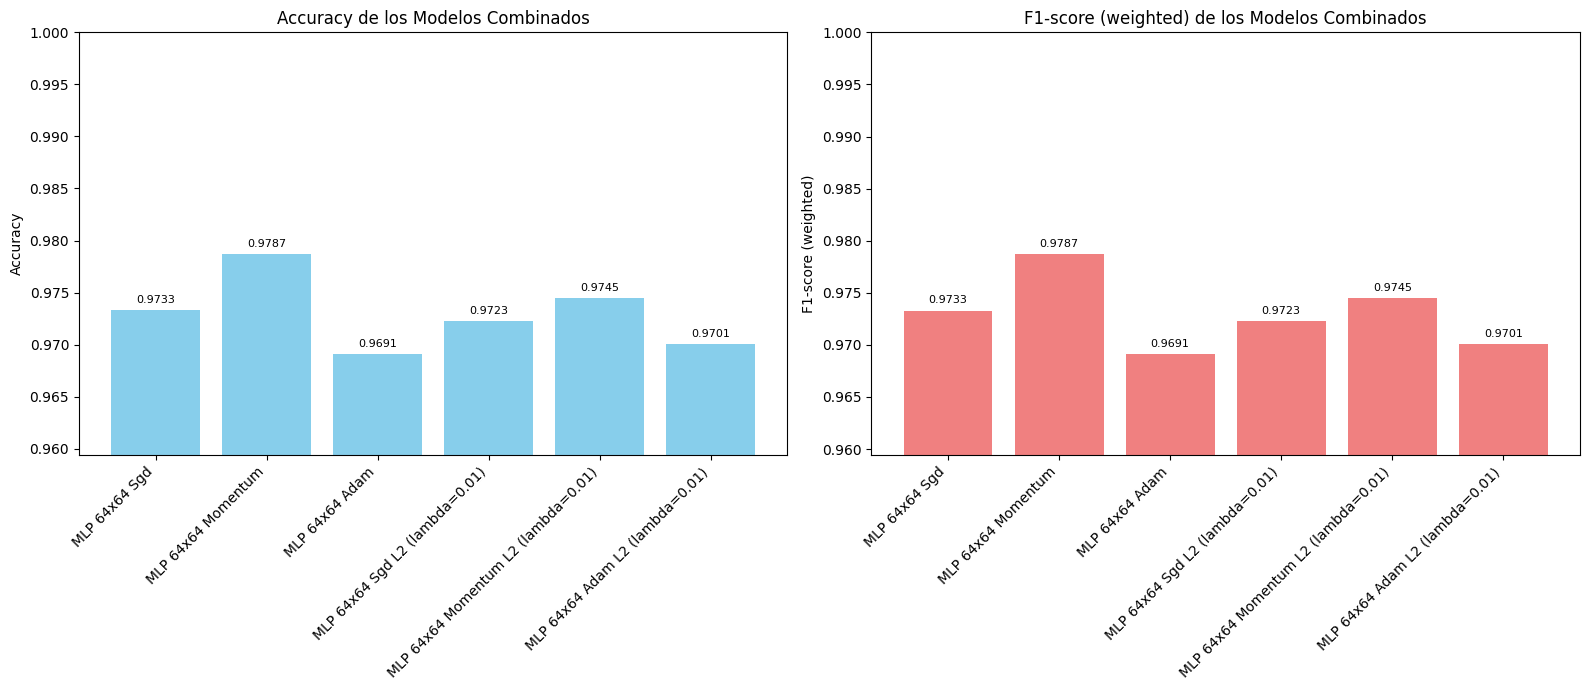

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Asegurarse de que model_performance_df sea global
global model_performance_df
global new_models_to_plot

# Filtrar model_performance_df para los nuevos modelos para la visualización
new_results_df = model_performance_df[model_performance_df['Model Name'].isin(new_models_to_plot)]

plt.figure(figsize=(16, 7))

# --- Gráfico de barras para Accuracy ---
plt.subplot(1, 2, 1)
accuracies = new_results_df['Accuracy'].values
min_accuracy = np.min(accuracies)

# Ajustar el límite inferior del eje Y, un poco por debajo del mínimo para visualización
plt.ylim(min_accuracy * 0.99, 1)

bars_accuracy = plt.bar(new_results_df['Model Name'], accuracies, color='skyblue')
plt.ylabel('Accuracy')
plt.title('Accuracy de los Modelos Combinados')
plt.xticks(rotation=45, ha='right')

# Mostrar el número encima de cada barra de Accuracy
for bar in bars_accuracy:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.0005, round(yval, 4), ha='center', va='bottom', fontsize=8)

# --- Gráfico de barras para F1-score (weighted) ---
plt.subplot(1, 2, 2)
f1_scores = new_results_df['F1-score (weighted)'].values
min_f1_score = np.min(f1_scores)

# Ajustar el límite inferior del eje Y, un poco por debajo del mínimo para visualización
plt.ylim(min_f1_score * 0.99, 1)

bars_f1 = plt.bar(new_results_df['Model Name'], f1_scores, color='lightcoral')
plt.ylabel('F1-score (weighted)')
plt.title('F1-score (weighted) de los Modelos Combinados')
plt.xticks(rotation=45, ha='right')

# Mostrar el número encima de cada barra de F1-score
for bar in bars_f1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.0005, round(yval, 4), ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()